# Principal component analysis of the environmental conditions associated with coral bleaching

**Methodology notebook · research question 2**

> *Can dimensionality reduction reveal the major environmental patterns associated with bleaching severity?*

## Objective and approach

Principal component analysis (PCA) is used to summarise the correlated environmental variables recorded for each coral survey sample into a small number of uncorrelated components. PCA is *unsupervised*: the components are computed from the environmental variables alone, without any use of the bleaching values. Bleaching severity is introduced only afterwards, to ask whether the components that the PCA found are the ones that differ between lightly and heavily bleached samples. The analysis therefore proceeds in four stages:

1. **Extraction.** Fit the PCA on the standardised environmental variables and decide how many components to retain (Step 3).
2. **Interpretation.** Read each component from its loadings, i.e. decide which environmental processes it describes (Step 4).
3. **Association with bleaching.** Test whether, and how strongly, the components separate samples with high bleaching from samples with low bleaching, and how much of that separation survives the dimension reduction (Steps 5 and 6).
4. **Validity.** Use the categorical columns (data source, region, ocean, exposure) to check that the components describe environmental patterns rather than differences between survey programmes (Steps 7 to 10).

## Operational definitions

| Term | Definition used in this notebook |
|---|---|
| Environmental variable | One of the numeric satellite-derived and site variables retained after preprocessing (temperature, temperature anomalies, thermal stress, degree heating weeks, turbidity, depth, distance to shore, cyclone frequency, wind speed). The exact list is read from the metadata of the preprocessing notebook. |
| Bleaching severity | `Percent_Bleaching`, grouped as **Low** (0–10 %), **Moderate** (>10–50 %) and **High** (>50 %), following the Reef Check severity classes. |
| Major environmental pattern | A retained principal component, i.e. an axis along which the samples vary strongly and which is made up of a coherent set of variables. |
| Associated with bleaching severity | A component whose scores differ between High and Low samples with a non-negligible effect size (Cliff's δ, Cohen's d), that stays significant after false-discovery-rate control, and that still separates the groups *within* each data source. |

## Input

The notebook reads `coral_pca_ready.csv`, written by the cleaning and preprocessing notebook (`coral_cleaning_preprocessing.ipynb`, folder `processed/`). Its main properties, taken from that notebook's metadata file (`coral_preprocessing_metadata.json`), are:
- **Unit of analysis:** one row per sample (`Sample_ID`). The raw file has one row per substrate record (41,361 rows); the preprocessing collapsed these to 27,005 samples, kept the 23,271 samples with an observed bleaching value, kept the 23,126 sampled in **1998 or later**, and removed 57 samples for which more than half of the environmental inputs were missing, leaving **23,069 samples**.
- **Environmental variables (PCA inputs):** 35 numeric variables. 31 were power-transformed (Yeo–Johnson) because they were skewed, and all 35 were standardised to mean 0 and standard deviation 1. Missing values were replaced by the column median (depth was imputed for 1,608 samples, which are flagged in `Depth_m_was_missing`). Two near-duplicate columns (`SSTA_Mean` and `TSA_Standard_Deviation`, absolute Spearman correlation of at least 0.999 with another column) were left out of the inputs, and `Substrate_Name` and `Percent_Cover` were removed because they differ between the substrate records of one sample.
- **Interpretation columns (not PCA inputs):** identifiers, date, location, the bleaching value (`Percent_Bleaching`) and group (`Bleaching_Group`), and the categorical columns (data source, ocean, realm, ecoregion, country, exposure and so on).

The metadata file lists the PCA input columns; the list of categorical columns is set in Step 1 (`CATEGORICAL_COLUMNS`). Step 2 validates the table before any analysis is run.

> **Note on the figures quoted in the text.** The results quoted in the markdown cells come from the run on the preprocessed table `coral_pca_ready.csv` of 23,069 samples and 35 environmental variables. If the preprocessing is changed (for example, other samples are removed), re-run the notebook and check each quoted figure against the new output before reporting it.

## Overview of the steps

| Step | Purpose | Main methods |
|---|---|---|
| 3 | Extract components and decide how many to keep | PCA, scree plot, Kaiser rule, parallel analysis |
| 4 | Interpret the components | Loadings (correlations), contributions, variable families |
| 5 | Relate the components to bleaching severity | Cliff's δ (AUC), Cohen's d, Spearman ρ, density plots (KDE) |
| 6 | Quantify the information kept by the components | Welch t-tests, Benjamini–Hochberg FDR, site-level tests, Hotelling T² |
| 7–8 | Relate the components to categorical features | ω² (variance explained by data source, region, ocean, exposure) |
| 9 | Control for data source | Within-source Cliff's δ and a source-adjusted δ |
| 10 | Test whether the structure depends on one source | PCA refitted per source, congruence of loadings |
| 11–12 | Save the results and answer the research question | |

## Reproducibility

All random procedures use `RANDOM_STATE = 42`. The notebook runs from top to bottom without manual steps and writes its tables to `outputs/pca/`.


## Setup · Libraries and output location

**Method.** The analysis uses `pandas` and `numpy` for the data, `scipy.stats` for the statistical tests, `scikit-learn` for the PCA and standardisation and `matplotlib` for the figures. The notebook is self-contained: the functions it needs are defined in the next cell, so no other file is required apart from the preprocessed table.

**Result.** No analysis is run in this step. If it fails, the missing package has to be installed.


In [1]:
import json
import re
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

OUT_DIR = Path("outputs")  # tables are written here

## Setup · Helper functions

**Method.** The statistical procedures that are used more than once are defined here, each with its documentation, so that the analysis steps below stay short:
- `fit_loadings` and `loading_congruence`: PCA loadings and the congruence coefficient between two sets of loadings;
- `auc_high_low` and `omega_squared`: effect sizes (AUC and Cliff's δ, bias-corrected ω²);
- `high_low_u` and `within_stratum_delta`: High-versus-Low comparison within each level of a categorical column, combined into a source-adjusted δ;
- `benjamini_hochberg`, `welch_high_low` and `hotelling_two_sample`: Welch t-tests with false-discovery-rate control and Hotelling's multivariate test.

**Result.** The cell only defines functions; it produces no output.


In [2]:
DEFAULT_COMPONENTS = 5
DEFAULT_SEED = 42


def auc_high_low(values, groups):
    """Probability that a High sample scores above a Low sample.

    ``values`` is a score per sample and ``groups`` the bleaching group of
    each sample ("Low", "Moderate" or "High"). 0.5 means no separation.
    """
    high, low = values[groups == "High"], values[groups == "Low"]
    u_stat = stats.mannwhitneyu(
        high, low, alternative="two-sided", method="asymptotic"
    ).statistic
    return u_stat / (len(high) * len(low))


def fit_loadings(frame, n_components=DEFAULT_COMPONENTS, seed=DEFAULT_SEED):
    """Fit a PCA on ``frame`` and return its loadings and variance ratios.

    The loadings are the eigenvectors (variables x components); the second
    value is the share of variance explained by each component.
    """
    model = PCA(n_components=n_components, random_state=seed)
    model.fit(frame.to_numpy())
    names = [f"PC{i + 1}" for i in range(n_components)]
    loadings = pd.DataFrame(
        model.components_.T, index=frame.columns, columns=names
    )
    return loadings, model.explained_variance_ratio_


def loading_congruence(reference, other, n_components=DEFAULT_COMPONENTS):
    """Match each reference component to its best component in ``other``.

    Congruence is the absolute cosine between loading vectors, so it ignores
    the arbitrary sign of a component. Returns the best congruence per
    reference component and the name of the matching component.
    """
    common = reference.index.intersection(other.index)
    ref = reference.loc[common].to_numpy()[:, :n_components].copy()
    oth = other.loc[common].to_numpy().copy()
    ref /= np.linalg.norm(ref, axis=0)
    oth /= np.linalg.norm(oth, axis=0)
    cosines = np.abs(ref.T @ oth)
    matches = [f"PC{i + 1}" for i in cosines.argmax(axis=1)]
    return cosines.max(axis=1), matches


def omega_squared(values, labels, min_n=50):
    """Bias-corrected share of variance in ``values`` between categories.

    Categories with fewer than ``min_n`` samples are pooled into "Other".
    The result is never negative.
    """
    labels = pd.Series(labels).astype(str)
    counts = labels.value_counts()
    labels = labels.where(labels.map(counts) >= min_n, "Other")
    data = pd.DataFrame(
        {"x": np.asarray(values, float), "group": labels.to_numpy()}
    )
    grand_mean = data.x.mean()
    n_obs, n_groups = len(data), data.group.nunique()
    between = (
        data.groupby("group")
        .x.agg(lambda v: len(v) * (v.mean() - grand_mean) ** 2)
        .sum()
    )
    total = ((data.x - grand_mean) ** 2).sum()
    within_mean_sq = (total - between) / (n_obs - n_groups)
    numerator = between - (n_groups - 1) * within_mean_sq
    omega = numerator / (total + within_mean_sq)
    return max(0.0, omega)


def high_low_u(values, mask, groups):
    """Mann-Whitney U statistic and pair count for High vs Low in ``mask``.

    Returns ``(u_statistic, n_pairs)``; ``(0, 0)`` if either group is empty.
    """
    high = values[mask & (groups == "High")]
    low = values[mask & (groups == "Low")]
    if len(high) == 0 or len(low) == 0:
        return 0, 0
    u_stat = stats.mannwhitneyu(
        high, low, alternative="two-sided", method="asymptotic"
    ).statistic
    return u_stat, len(high) * len(low)


def within_stratum_delta(frame, groups, strata_col, columns, min_n=30):
    """High-vs-Low Cliff's delta inside each level of a categorical column.

    ``columns`` maps a name to an array of scores (one per row of
    ``frame``). Only levels with at least ``min_n`` High and ``min_n`` Low
    samples are kept. Returns the per-level table and a dictionary with the
    stratified (source-adjusted) delta per column, in which each level is
    weighted by its number of High x Low pairs.
    """
    labels = frame[strata_col]
    levels = [
        level
        for level in labels.value_counts().index
        if ((labels == level) & (groups == "High")).sum() >= min_n
        and ((labels == level) & (groups == "Low")).sum() >= min_n
    ]
    rows, u_total, pair_total = [], {name: 0.0 for name in columns}, 0
    for level in levels:
        mask = (labels == level).to_numpy()
        n_high = int((mask & (groups == "High")).sum())
        n_low = int((mask & (groups == "Low")).sum())
        row = {strata_col: level, "n_high": n_high, "n_low": n_low}
        for name, scores in columns.items():
            u_stat, n_pairs = high_low_u(scores, mask, groups)
            row[name] = 2 * u_stat / n_pairs - 1
            u_total[name] += u_stat
        pair_total += n_high * n_low
        rows.append(row)
    table = pd.DataFrame(rows).set_index(strata_col)
    adjusted = {name: 2 * u_total[name] / pair_total - 1 for name in columns}
    return table, adjusted


def benjamini_hochberg(p_values):
    """Benjamini-Hochberg adjusted p-values (q-values) controlling the FDR.

    ``p_values`` is a one-dimensional array of raw p-values. The result has
    the same order; a q-value below 0.05 means the finding stays significant
    while keeping the expected share of false discoveries at 5 %.
    """
    p_values = np.asarray(p_values, dtype=float)
    n_tests = len(p_values)
    order = np.argsort(p_values)
    scaled = p_values[order] * n_tests / np.arange(1, n_tests + 1)
    adjusted = np.minimum.accumulate(scaled[::-1])[::-1]
    result = np.empty(n_tests)
    result[order] = np.minimum(adjusted, 1.0)
    return result


def welch_high_low(columns, groups, sites=None):
    """Welch t-test of High versus Low bleaching for several columns.

    ``columns`` maps a name to an array with one value per sample and
    ``groups`` gives the bleaching group of each sample. Returns one row per
    column with the mean difference (High - Low), its 95 % confidence
    interval, Cohen's d, the Welch p-value and the Benjamini-Hochberg q-value
    over all columns. If ``sites`` (a site label per sample) is given, the
    test is repeated on site means (the mean of the High samples of each
    site against the mean of the Low samples of each site), which respects
    that samples from one site are not independent.
    """
    is_high, is_low = groups == "High", groups == "Low"
    rows = []
    for name, values in columns.items():
        values = np.asarray(values, dtype=float)
        high, low = values[is_high], values[is_low]
        test = stats.ttest_ind(high, low, equal_var=False)
        interval = test.confidence_interval()
        pooled_sd = np.sqrt(
            (
                (len(high) - 1) * high.var(ddof=1)
                + (len(low) - 1) * low.var(ddof=1)
            )
            / (len(high) + len(low) - 2)
        )
        row = {
            "variable": name,
            "mean_high": high.mean(),
            "mean_low": low.mean(),
            "difference": high.mean() - low.mean(),
            "ci95_low": interval.low,
            "ci95_high": interval.high,
            "cohens_d": (high.mean() - low.mean()) / pooled_sd,
            "t": test.statistic,
            "df": test.df,
            "p": test.pvalue,
        }
        if sites is not None:
            frame = pd.DataFrame(
                {"value": values, "site": sites, "group": groups}
            )
            site_means = frame.groupby(["group", "site"]).value.mean()
            site_high = site_means.loc["High"].to_numpy()
            site_low = site_means.loc["Low"].to_numpy()
            site_test = stats.ttest_ind(site_high, site_low, equal_var=False)
            site_sd = np.sqrt(
                (
                    (len(site_high) - 1) * site_high.var(ddof=1)
                    + (len(site_low) - 1) * site_low.var(ddof=1)
                )
                / (len(site_high) + len(site_low) - 2)
            )
            row["site_level_d"] = (
                site_high.mean() - site_low.mean()
            ) / site_sd
            row["site_level_p"] = site_test.pvalue
        rows.append(row)
    table = pd.DataFrame(rows).set_index("variable")
    table["q_bh"] = benjamini_hochberg(table["p"].to_numpy())
    if sites is not None:
        table["site_level_q_bh"] = benjamini_hochberg(
            table["site_level_p"].to_numpy()
        )
    return table


def hotelling_two_sample(high, low):
    """Hotelling's two-sample T-squared test for High versus Low.

    ``high`` and ``low`` are arrays (samples x variables). Returns the
    squared Mahalanobis distance between the two group means (a multivariate
    effect size that does not depend on the sample size), the F statistic and
    its p-value. A generalised inverse is used so that strongly correlated
    variables do not break the calculation.
    """
    n_high, n_low, n_vars = len(high), len(low), high.shape[1]
    diff = high.mean(axis=0) - low.mean(axis=0)
    pooled = (
        (n_high - 1) * np.cov(high, rowvar=False)
        + (n_low - 1) * np.cov(low, rowvar=False)
    ) / (n_high + n_low - 2)
    mahalanobis_sq = float(diff @ np.linalg.pinv(pooled) @ diff)
    t_squared = mahalanobis_sq * n_high * n_low / (n_high + n_low)
    df_2 = n_high + n_low - n_vars - 1
    f_stat = t_squared * df_2 / ((n_high + n_low - 2) * n_vars)
    return {
        "mahalanobis_sq": mahalanobis_sq,
        "F": f_stat,
        "df1": n_vars,
        "df2": df_2,
        "p": float(stats.f.sf(f_stat, n_vars, df_2)),
    }

## Step 1 · Configuration

**Method.** All settings are collected in one cell so that the analysis can be reproduced and varied from a single place:
- the location of the preprocessed table and its metadata file;
- the column names and the bleaching groups (Low, Moderate, High);
- the columns that must never become PCA inputs (`NON_FEATURES`: identifiers, bleaching value and group, date and location);
- the number of components interpreted in depth (`N_INTERPRET = 5`), the number of permutations of the parallel analysis (`PARALLEL_PERMS = 50`) and the random seed (`RANDOM_STATE = 42`);
- two optional settings for tables that come without a metadata file: `PCA_INPUT_COLUMNS` (an explicit list of the PCA input columns) and `CATEGORICAL_COLUMNS` (the categorical columns used for interpretation);
- the plotting style (one blue hue from light to dark for increasing bleaching).

**Result.** No analysis is run in this step. `N_INTERPRET = 5` was fixed after the retention step (Step 3): the first five components explain 69 % of the variance and each explains at least 5.6 %, whereas components 6 and 7 each explain less than 4 %.


In [3]:
# Step 1 · Configuration
# ---------------- files ----------------
INPUT_CANDIDATES = [
    Path("processed") / "coral_pca_ready.csv",
    Path("..") / "processed" / "coral_pca_ready.csv",
    Path("..")
    / ".."
    / "Lab 2"
    / "DMW1_Coral-main"
    / "processed"
    / "coral_pca_ready.csv",
]  # table from the cleaning and preprocessing notebook (first found)
META_FILE = (
    OUT_DIR / "coral_preprocessing_metadata.json"
)  # lists which columns are PCA inputs
PCA_DIR = OUT_DIR / "pca"
PCA_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- column names ----------------
SAMPLE, SITE, TARGET = "Sample_ID", "Site_ID", "Percent_Bleaching"
GROUP_COL = "Bleaching_Group"
GROUP_ORDER = ["Low", "Moderate", "High"]
YEAR, MONTH, LAT = "Date_Year", "Date_Month", "Latitude_Degrees"
FLAG_IMPUTED = "Depth_m_was_missing"
NON_FEATURES = [
    SAMPLE,
    SITE,
    TARGET,
    GROUP_COL,
    FLAG_IMPUTED,
    "Date",
    "Date_Day",
    MONTH,
    YEAR,
    LAT,
    "Longitude_Degrees",
]

# ---------------- analysis settings ----------------
# components interpreted in depth (the heatmaps show every retained component)
N_INTERPRET = 5
PARALLEL_PERMS = 50  # permutations for parallel analysis
RANDOM_STATE = 42

# ---- settings for tables that come without a metadata file ----
# Explicit list of PCA input columns; None = take them from the
# metadata file, or infer them from the numeric columns.
PCA_INPUT_COLUMNS = None
# Categorical columns used to interpret the PCA (only the ones that
# exist in the table are used; the metadata file overrides this).
CATEGORICAL_COLUMNS = [
    "Data_Source",
    "Ocean_Name",
    "Realm_Name",
    "Ecoregion_Name",
    "Country_Name",
    "State_Island_Province_Name",
    "City_Town_Name",
    "Site_Name",
    "Reef_ID",
    "Exposure",
]

# ---------------- plotting ----------------
GROUP_COLORS = {
    "Low": "#a9c4e3",
    "Moderate": "#2a78d6",
    "High": "#0b2f66",
}  # one hue, light -> dark = increasing bleaching
C_POS, C_NEG, C_MUTED = "#2a78d6", "#d9622b", "#8a8984"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c9c8c2",
        "axes.grid": True,
        "grid.color": "#ecebe7",
        "axes.axisbelow": True,
        "axes.titlesize": 10,
        "axes.titleweight": "bold",
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
    }
)
pd.set_option(
    "display.max_columns",
    100,
    "display.max_rows",
    200,
    "display.width",
    200,
    "display.float_format",
    lambda v: f"{v:,.4g}",
)

## Step 2 · Data loading and validation

**Method.** The preprocessed table is loaded and validated before the PCA is run. The notebook stops with an error if any of the following checks fails:
- the PCA inputs are numeric and contain no missing values;
- no date, bleaching value or bleaching group is among the inputs;
- the categorical columns are present and none of them is an input;
- there is one row per sample, every sample has a bleaching group, and the number of samples exceeds five times the number of inputs.

The inputs are expected to be standardised already (mean 0, standard deviation 1); if the deviation exceeds 10⁻³ they are standardised here, so that the PCA is always computed on the correlation matrix. The PCA input columns are taken, in order of priority, from the explicit list `PCA_INPUT_COLUMNS` (Step 1), from the metadata file stored next to the table, or, if neither exists, inferred from the numeric columns that are not identifiers, dates, locations or bleaching columns (a warning is then printed and the list should be checked). The categorical columns come from the metadata file or, without it, from the list `CATEGORICAL_COLUMNS` (Step 1). A second cell assigns each input to an *environmental family* (temperature, anomalies, degree heating weeks and so on) from its name, so that the loadings can later be summarised by the type of variable.

**Results.**
- The table contained 23,069 samples and 35 PCA inputs. All validation checks passed and the inputs were already standardised (maximum deviation 4×10⁻¹⁵).
- The bleaching groups were unbalanced: Low 16,905 samples (73.3 %), Moderate 3,986 (17.3 %) and High 2,178 (9.4 %). Effect sizes and medians are therefore used rather than significance alone in the later steps.
- The families contain 5 sea-surface-temperature variables, 1 temperature-variability variable, 4 SSTA, 4 TSA, 8 anomaly-frequency, 8 degree-heating-week variables, and one variable each for turbidity, depth, distance to shore, cyclone frequency and wind speed. **The thermal variables therefore make up most of the inputs (30 of 35)** and are expected to dominate the first components. This reflects how many variables describe temperature, not necessarily how important temperature is.
- `Percent_Cover` is not an input: it is reported per substrate type and has no meaning once the rows are collapsed to one per sample.


In [4]:
# Step 2 · Load the data and check it is PCA-ready
path = next((p for p in INPUT_CANDIDATES if p.exists()), None)
if path is None:
    raise FileNotFoundError(
        "PCA input not found. Looked for: "
        + ", ".join(map(str, INPUT_CANDIDATES))
    )
df = pd.read_csv(path, low_memory=False)
META_FILE = path.parent / META_FILE.name  # next to the table
meta = (
    json.loads(META_FILE.read_text(encoding="utf-8"))
    if META_FILE.exists()
    else {}
)
print(f"Loaded {path}  →  {len(df):,} rows × {df.shape[1]} columns")

if PCA_INPUT_COLUMNS:
    absent = [c for c in PCA_INPUT_COLUMNS if c not in df.columns]
    assert not absent, f"PCA_INPUT_COLUMNS not in the table: {absent}"
    features = list(PCA_INPUT_COLUMNS)
elif meta.get("pca_input_columns"):
    features = [c for c in meta["pca_input_columns"] if c in df.columns]
else:  # fall back to "every numeric column that is not an ID / date / outcome"
    features = [
        c for c in df.select_dtypes("number").columns if c not in NON_FEATURES
    ]
    print(
        "WARNING: no metadata file found next to the table; the "
        "PCA inputs were inferred from the numeric columns. "
        "Check the list below."
    )
if not meta.get("categorical_columns"):
    meta["categorical_columns"] = [
        c for c in CATEGORICAL_COLUMNS if c in df.columns
    ]
    print(
        "Categorical columns taken from CATEGORICAL_COLUMNS: "
        f"{meta['categorical_columns']}"
    )
interp = [c for c in df.columns if c not in features]
print(
    f"PCA inputs: {len(features)}   |   interpretation-only columns: {interp}"
)

df[GROUP_COL] = pd.Categorical(
    df[GROUP_COL], categories=GROUP_ORDER, ordered=True
)
X = df[features].astype(float)

checks = {
    "no missing values": int(X.isna().sum().sum()) == 0,
    "all inputs numeric": all(
        pd.api.types.is_numeric_dtype(df[c]) for c in features
    ),
    "no date columns among the inputs": not (
        {YEAR, MONTH, "Date_Day", "Date"} & set(features)
    ),
    "bleaching value / group not among inputs": not (
        {TARGET, GROUP_COL} & set(features)
    ),
    "categorical columns present, none among the inputs": all(
        c in df.columns for c in meta.get("categorical_columns", [])
    )
    and not (set(meta.get("categorical_columns", [])) & set(features)),
    "one row per sample": df[SAMPLE].is_unique,
    "every sample has a bleaching group": df[GROUP_COL].notna().all(),
    "more samples than 5 × features": len(df) > 5 * len(features),
}
print(pd.Series(checks).map({True: "✔ pass", False: "✘ FAIL"}).to_string())
assert all(checks.values())

dev = max(X.mean().abs().max(), (X.std(ddof=0) - 1).abs().max())
if dev > 1e-3:
    X = pd.DataFrame(
        StandardScaler().fit_transform(X), columns=features, index=df.index
    )
    print(
        f"\nInputs were not standardised (deviation {dev:.3g}) → standardised "
        "here."
    )
else:
    print(
        "\nInputs are already standardised (mean 0, sd 1; max deviation "
        f"{dev:.1e}) — no further scaling needed."
    )

cnt = df[GROUP_COL].value_counts().reindex(GROUP_ORDER)
display(
    pd.DataFrame(
        {
            "samples": cnt,
            "pct": 100 * cnt / cnt.sum(),
            "median_bleaching_%": df.groupby(GROUP_COL, observed=True)[
                TARGET
            ].median(),
        }
    )
)

Loaded processed\coral_pca_ready.csv  →  23,069 rows × 62 columns
Categorical columns taken from CATEGORICAL_COLUMNS: ['Data_Source', 'Ocean_Name', 'Realm_Name', 'Ecoregion_Name', 'Country_Name', 'State_Island_Province_Name', 'City_Town_Name', 'Site_Name', 'Reef_ID', 'Exposure']
PCA inputs: 35   |   interpretation-only columns: ['Sample_ID', 'Site_ID', 'Data_Source', 'Latitude_Degrees', 'Longitude_Degrees', 'Ocean_Name', 'Reef_ID', 'Realm_Name', 'Ecoregion_Name', 'Country_Name', 'State_Island_Province_Name', 'City_Town_Name', 'Site_Name', 'Exposure', 'Date_Day', 'Date_Month', 'Date_Year', 'Bleaching_Level', 'SSTA_Mean', 'TSA_Standard_Deviation', 'Date', 'Site_Comments', 'Sample_Comments', 'Bleaching_Comments', 'Percent_Bleaching', 'Bleaching_Group', 'Depth_m_was_missing']
no missing values                                     ✔ pass
all inputs numeric                                    ✔ pass
no date columns among the inputs                      ✔ pass
bleaching value / group not among 

,samples,pct,median_bleaching_%
Bleaching_Group,,,
Low,16905,73.28,0
Moderate,3986,17.28,27.3
High,2178,9.441,75


**Environmental families.** Each input was assigned to one family by its name, using an ordered set of rules.


In [5]:
# ---- group the variables into environmental families, used to read the
# loadings ----
FAMILY_RULES = [  # first match wins
    ("Turbidity", r"^Turbidity$"),
    ("Depth", r"^Depth_m$"),
    ("Cyclone frequency", r"^Cyclone_Frequency$"),
    ("Distance to shore", r"^Distance_to_Shore$"),
    ("Wind speed", r"^Windspeed$"),
    ("Degree heating weeks (DHW)", r"DHW"),
    ("Anomaly frequency", r"Frequency"),
    ("TSA (thermal stress anomaly)", r"^TSA"),
    ("SSTA (SST anomaly)", r"^SSTA"),
    ("Temperature variability", r"^Temperature.*Standard_Deviation"),
    ("Sea surface temperature (SST)", r"^(ClimSST|Temperature)"),
]
FAMILY_ORDER = [
    "Sea surface temperature (SST)",
    "Temperature variability",
    "SSTA (SST anomaly)",
    "TSA (thermal stress anomaly)",
    "Anomaly frequency",
    "Degree heating weeks (DHW)",
    "Turbidity",
    "Depth",
    "Distance to shore",
    "Cyclone frequency",
    "Wind speed",
    "Other",
]


def family(name):
    return next(
        (f for f, pat in FAMILY_RULES if re.search(pat, name)), "Other"
    )


fam = pd.Series({c: family(c) for c in features}, name="family")
display(
    fam.value_counts()
    .reindex(FAMILY_ORDER)
    .dropna()
    .astype(int)
    .rename("variables")
    .to_frame()
)
FEATURE_ORDER = sorted(features, key=lambda c: (FAMILY_ORDER.index(fam[c]), c))

,variables
family,
Sea surface temperature (SST),5
Temperature variability,1
SSTA (SST anomaly),4
TSA (thermal stress anomaly),4
Anomaly frequency,8
Degree heating weeks (DHW),8
Turbidity,1
Depth,1
Distance to shore,1


## Step 3 · Extraction of components and number of components retained

**Method.** A PCA was fitted to the standardised inputs, which is equivalent to an eigen-decomposition of their correlation matrix. Three criteria were used together to decide how many components to retain:
- the **scree plot**, in which the elbow marks where eigenvalues level off;
- the **Kaiser rule**, which keeps components with an eigenvalue above 1 (they explain more than one standardised variable);
- **parallel analysis**, which keeps components whose eigenvalue exceeds the 95th percentile of the eigenvalues obtained from column-shuffled, structure-free data (50 permutations). Parallel analysis was the deciding criterion because the Kaiser rule is known to over-retain components.

**Results.**
- The leading components were not dominant: PC1 explained 30.0 % of the variance, and 9 components were needed for 80 % and 14 for 90 %. The 35 variables therefore carry several distinct patterns rather than one overwhelming axis.
- The scree plot flattened after about 5 to 7 components. The Kaiser rule retained 8 components and parallel analysis retained 7 (the eighth eigenvalue, 1.02, was only just above 1 and did not exceed the shuffled-data threshold of 1.04).
- **Seven components were retained, explaining 75.9 % of the variance.** The first five (69.0 %) were interpreted in depth; components 6 and 7 appear in the heatmaps but each explains less than 4 %.


**PCA fit and parallel analysis.** The PCA was fitted, parallel analysis was run on shuffled copies of the data, and the number of components suggested by each criterion was printed.


In [6]:
# Step 3 · Fit the PCA and decide how many components to interpret
x_values = X.to_numpy()
pca = PCA(random_state=RANDOM_STATE).fit(x_values)
eigenvalues = pca.explained_variance_
var_ratio = pca.explained_variance_ratio_
cumulative_ratio = np.cumsum(var_ratio)
p = len(features)
pc_names = [f"PC{i+1}" for i in range(p)]

# parallel analysis: eigenvalues of correlation matrices of column-shuffled
# data
rng = np.random.default_rng(RANDOM_STATE)
rand = np.empty((PARALLEL_PERMS, p))
for i in range(PARALLEL_PERMS):
    Xp = np.column_stack([rng.permutation(x_values[:, j]) for j in range(p)])
    rand[i] = np.sort(np.linalg.eigvalsh(np.corrcoef(Xp, rowvar=False)))[::-1]
parallel_p95 = np.percentile(rand, 95, axis=0)

K_KAISER = int((eigenvalues > 1).sum())
K_PARALLEL = int((eigenvalues > parallel_p95).sum())
K_80, K_90 = (
    int(np.searchsorted(cumulative_ratio, 0.80)) + 1,
    int(np.searchsorted(cumulative_ratio, 0.90)) + 1,
)
K_RETAIN = min(K_KAISER, K_PARALLEL)
variance_table = pd.DataFrame(
    {
        "eigenvalue": eigenvalues,
        "variance_%": 100 * var_ratio,
        "cumulative_%": 100 * cumulative_ratio,
        "parallel_95th": parallel_p95,
    },
    index=pc_names,
)
display(variance_table.head(max(12, K_RETAIN + 2)))
print(
    f"Kaiser (eigenvalue > 1): {K_KAISER} | parallel analysis: {K_PARALLEL} | "
    f"80% of variance: {K_80} | 90%: {K_90}"
)
print(
    f"→ retaining the first {K_RETAIN} components "
    f"({100*cumulative_ratio[K_RETAIN-1]:.1f}% of the variance); interpreting "
    f"the first {N_INTERPRET} in depth "
    f"({100*cumulative_ratio[N_INTERPRET-1]:.1f}%)"
)

,eigenvalue,variance_%,cumulative_%,parallel_95th
PC1,10.49,29.96,29.96,1.079
PC2,5.866,16.76,46.72,1.069
PC3,3.301,9.43,56.15,1.064
PC4,2.523,7.208,63.36,1.057
PC5,1.986,5.675,69.03,1.053
PC6,1.35,3.858,72.89,1.048
PC7,1.048,2.995,75.88,1.043
PC8,1.016,2.904,78.79,1.039
PC9,0.9587,2.739,81.53,1.035
PC10,0.7827,2.236,83.76,1.032


Kaiser (eigenvalue > 1): 8 | parallel analysis: 7 | 80% of variance: 9 | 90%: 14
→ retaining the first 7 components (75.9% of the variance); interpreting the first 5 in depth (69.0%)


**Scree plot and cumulative variance.** The eigenvalues and the cumulative explained variance, with the retained components marked.


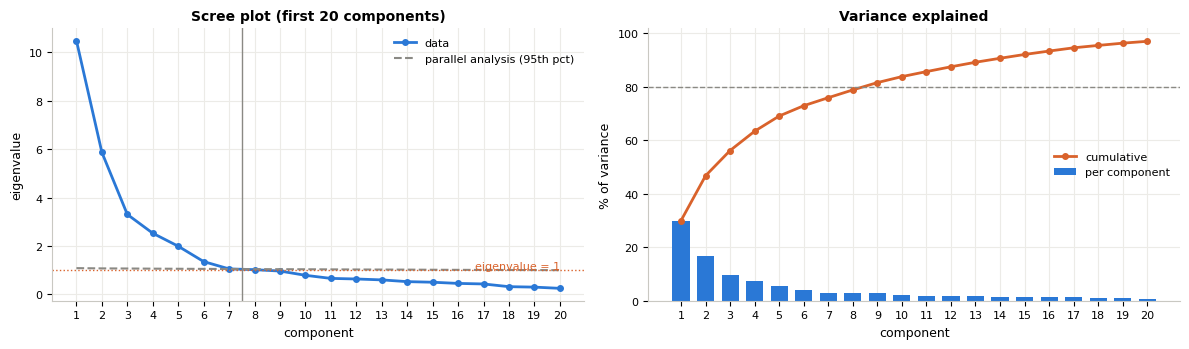

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
k = np.arange(1, 21)
ax.plot(k, eigenvalues[:20], "o-", color=C_POS, lw=2, ms=4, label="data")
ax.plot(
    k,
    parallel_p95[:20],
    "--",
    color=C_MUTED,
    lw=1.5,
    label="parallel analysis (95th pct)",
)
ax.axhline(1, color=C_NEG, lw=1, ls=":")
ax.text(20, 1.05, "eigenvalue = 1", ha="right", color=C_NEG, fontsize=8)
ax.axvline(K_RETAIN + 0.5, color=C_MUTED, lw=1)
ax.set_xticks(k)
ax.set_xlabel("component")
ax.set_ylabel("eigenvalue")
ax.set_title("Scree plot (first 20 components)")
ax.legend()
ax = axes[1]
ax.bar(
    np.arange(1, 21),
    100 * var_ratio[:20],
    color=C_POS,
    width=0.7,
    label="per component",
)
ax.plot(
    np.arange(1, 21),
    100 * cumulative_ratio[:20],
    "o-",
    color=C_NEG,
    ms=4,
    lw=2,
    label="cumulative",
)
ax.axhline(80, color=C_MUTED, lw=1, ls="--")
ax.set_xticks(np.arange(1, 21))
ax.set_xlabel("component")
ax.set_ylabel("% of variance")
ax.set_title("Variance explained")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

**What the figure shows.** *Left (scree plot):* the eigenvalue of each component against the two retention benchmarks. The first component has an eigenvalue of 10.5 and the second 5.9; the curve then drops steeply and flattens after about the seventh component. The dotted line marks the Kaiser threshold (eigenvalue = 1) and the dashed line marks the 95th percentile of eigenvalues from permuted data (parallel analysis, about 1.04–1.08). PC7 (1.048) lies just above the parallel-analysis line and PC8 (1.016) lies below it, which fixes the cut-off at seven components (the vertical line); the Kaiser rule alone would keep eight. *Right (variance explained):* the bars give the share of variance per component (PC1 30.0 %, PC2 16.8 %, PC3 9.4 %, PC4 7.2 %) and the line gives the cumulative share, which reaches 75.9 % at seven components and passes 80 % only at PC9. The figure therefore justifies keeping seven components and shows that a small number of components summarise most of the 35 variables, while the long tail means that no short summary captures everything.


## Step 4 · Interpretation of the components from their loadings

**Method.** For standardised data the **loading** of a variable on a component equals the correlation between that variable and the component's scores (−1 to +1); a large positive or negative loading means that the variable moves with the component. A variable's **contribution** to a component is its squared eigenvector weight, and the contributions of all variables to one component sum to 100 %. The sign of a component is arbitrary, so every component was oriented so that its largest-magnitude loading is positive. To interpret the components, the variable definitions of the data dictionary were used: variables ending in *Mean*, *Max*, *Min* or *Standard_Deviation* summarise the **whole record of a site** (its long-term climatology); `SSTA`, `TSA` and `Temperature_Kelvin` are the **weekly value at the time of sampling**; the `*_DHW` variables accumulate the **previous 12 weeks**; and the `*_Frequency` variables count anomalies over the **previous 52 weeks**.

**Results.** The components split almost exactly along the line between long-term climatology and recent conditions:

| Component | Variance | Interpretation | Strongest loadings |
|---|:-:|---|---|
| **PC1** | 30 % | **Long-term heat-stress history of the site**: how often, how strongly and how variably the site has been heat-stressed over the record | `SSTA_DHW_Standard_Deviation` +0.94, `SSTA_DHWMean` +0.90, `SSTA_DHWMax` +0.87, `SSTA_FrequencyMean` +0.85, `TSA_DHW_Standard_Deviation` +0.82; also `Turbidity` +0.52 |
| **PC2** | 17 % | **Typical thermal regime**: warm, thermally stable water (high) versus cooler water with a large seasonal swing (low) | `TSA_Mean` +0.91, `Temperature_Minimum` +0.88, `TSA_Minimum` +0.85, `Temperature_Mean` +0.78; `Temperature_Kelvin_Standard_Deviation` −0.86 |
| **PC3** | 9 % | **Heat stress at the time of the survey**: warm water with positive anomalies and recent degree heating weeks, in calm wind | `Temperature_Kelvin` +0.84, `TSA` +0.80, `SSTA` +0.63, `SSTA_DHW` +0.58, `TSA_DHW` +0.54; `Windspeed` −0.40 |
| **PC4** | 7 % | **Repeated heat stress over the past year, relative to a cooler normal**: frequent anomalies and accumulated DHW at sites with lower typical SST and clearer water | `TSA_Frequency` +0.61, `TSA_DHW` +0.50, `SSTA_DHW` +0.46, `SSTA_Frequency` +0.46, `Windspeed` +0.45; `ClimSST` −0.54, `Temperature_Maximum` −0.51, `Turbidity` −0.37 |
| **PC5** | 6 % | Variable anomaly frequency (high) versus extreme maximum anomalies (low), with distance to shore on the low side (less clear-cut) | `SSTA_Frequency_Standard_Deviation` +0.58, `SSTA_FrequencyMax` +0.57; `TSA_Maximum` −0.58, `SSTA_Maximum` −0.50, `Distance_to_Shore` −0.35 |

Further findings from the loadings:
- Degree heating weeks and anomaly frequency make up 76 % of PC1 and nearly half of PC4; PC2 is just over half SST and TSA variables (the "typical temperature" variables). The thermal variables dominate because there are 30 of them; this is a property of the data and not evidence that temperature is the most important factor.
- Turbidity, depth, distance to shore, cyclone frequency and wind do not form a major pattern of their own in components 1 to 5 (each contributes under 10 % to any of them; wind and turbidity reach 8 % and 6 % of PC4). They are largely independent of the thermal block and appear mainly in PC7, where depth alone accounts for 54 % of the component.


**Loadings and contributions.** The loading and contribution of every variable were computed for the retained components, and the components were oriented as described above.

In [8]:
# Step 4 · Loadings: which variables define each component?
comps = pca.components_.copy()  # (component, variable)
scores_all = pca.transform(x_values)
sign = np.sign(comps[np.arange(p), np.abs(comps).argmax(axis=1)])
sign[sign == 0] = 1
comps *= sign[:, None]
scores_all *= sign[None, :]
loadings = pd.DataFrame(
    comps.T * np.sqrt(eigenvalues), index=features, columns=pc_names
)  # correlation loadings
contrib = pd.DataFrame(
    comps.T**2 * 100, index=features, columns=pc_names
)  # % contribution (per component)
scores = pd.DataFrame(scores_all, index=df.index, columns=pc_names)
fam_contrib = (
    contrib.groupby(fam)
    .sum()
    .reindex([f for f in FAMILY_ORDER if f in set(fam)])
)

**Loadings heatmap.** The loadings of all variables on the retained components, with the variables ordered by family.

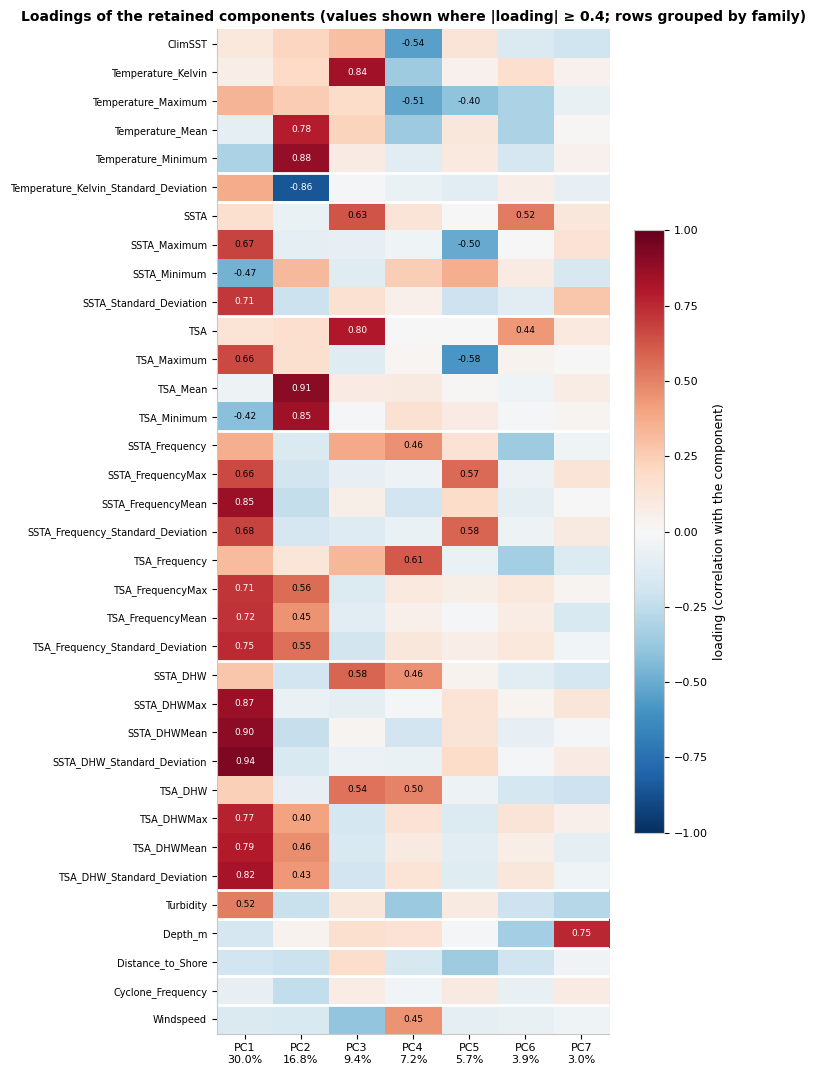

In [9]:
# ---- heatmap of loadings for the retained components ----
show = pc_names[:K_RETAIN]
L = loadings.loc[FEATURE_ORDER, show]
fig, ax = plt.subplots(figsize=(1.0 + 0.9 * K_RETAIN, 0.27 * len(L) + 1.4))
im = ax.imshow(L, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.grid(False)
ax.set_xticks(range(K_RETAIN))
ax.set_xticklabels(
    [f"{c}\n{100*var_ratio[i]:.1f}%" for i, c in enumerate(show)]
)
ax.set_yticks(range(len(L)))
ax.set_yticklabels(L.index, fontsize=7)
for i in range(L.shape[0]):
    for j in range(L.shape[1]):
        v = L.iloc[i, j]
        if abs(v) >= 0.4:
            ax.text(
                j,
                i,
                f"{v:.2f}",
                ha="center",
                va="center",
                fontsize=6.5,
                color="white" if abs(v) > 0.7 else "black",
            )
edges = (
    np.cumsum(
        [
            sum(fam[c] == f for c in FEATURE_ORDER)
            for f in FAMILY_ORDER
            if f in set(fam)
        ]
    )[:-1]
    - 0.5
)
for e in edges:
    ax.axhline(e, color="white", lw=2)
fig.colorbar(
    im, ax=ax, shrink=0.6, label="loading (correlation with the component)"
)
ax.set_title(
    "Loadings of the retained components (values shown where |loading| ≥ 0.4; "
    "rows grouped by family)"
)
plt.tight_layout()
plt.show()

**What the figure shows.** The heatmap lists the loading (correlation with the component) of every variable on each retained component, with the variables grouped by environmental family and values printed where |loading| ≥ 0.4. Red cells move with the component and blue cells move against it. Each column has its own block of strong cells: PC1 is dominated by the long-term degree-heating-week and anomaly-frequency variables, PC2 by the typical-temperature variables (positive) against the seasonal temperature swing (negative), PC3 by the weekly temperature and anomaly values at the time of sampling, and PC4 by recent anomaly frequency and accumulated degree heating weeks together with a negative loading on typical sea-surface temperature. The figure shows that the components are not arbitrary mixtures: each is carried by a coherent group of related variables, which is what allows them to be named in the table above. Components 6 and 7 have few strong loadings and are harder to interpret.


**Strongest variables.** The variables with the largest absolute loadings on each of the first five components.

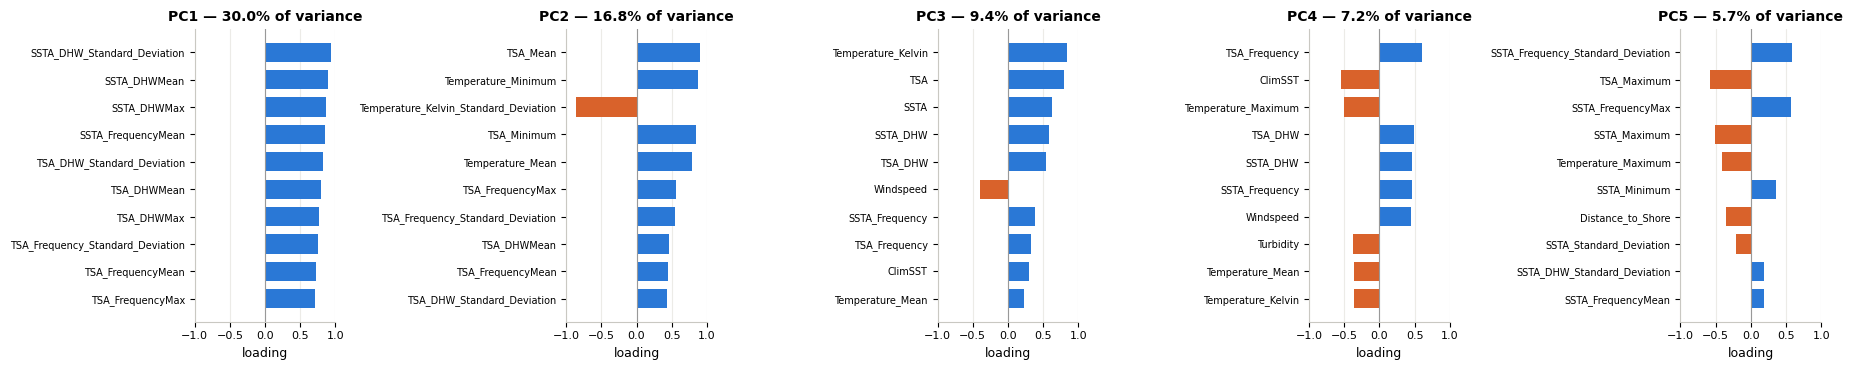

In [10]:
# ---- strongest variables per interpreted component ----
fig, axes = plt.subplots(1, N_INTERPRET, figsize=(3.7 * N_INTERPRET, 3.8))
for ax, c in zip(axes, pc_names[:N_INTERPRET]):
    top = (
        loadings[c]
        .reindex(loadings[c].abs().sort_values(ascending=False).index[:10])
        .iloc[::-1]
    )
    ax.barh(
        top.index,
        top.values,
        color=[C_POS if v > 0 else C_NEG for v in top],
        height=0.7,
    )
    ax.axvline(0, color="#999", lw=0.8)
    ax.set_xlim(-1, 1)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{c} — {100*var_ratio[pc_names.index(c)]:.1f}% of variance")
    ax.set_xlabel("loading")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

**What the figure shows.** For each of the first five components, the ten variables with the largest absolute loadings are drawn as horizontal bars (blue positive, red negative; the axis runs from −1 to +1). The bars confirm the interpretation of the heatmap with the actual values: PC1 reaches loadings of about +0.9 on long-term heat-stress variability and degree heating weeks, PC2 +0.91 on mean temperature anomaly and −0.86 on temperature variability, PC3 +0.84 on the temperature at the time of the survey, and PC4 loads positively on the recent anomaly frequency and degree heating weeks and negatively on the typical sea-surface temperature. Only a few variables per component carry loadings above 0.7, and the leading variables of different components differ, so each component describes a distinct aspect of the environment rather than repeating the same signal.


**Families.** The share of each component's contributions that comes from each environmental family.

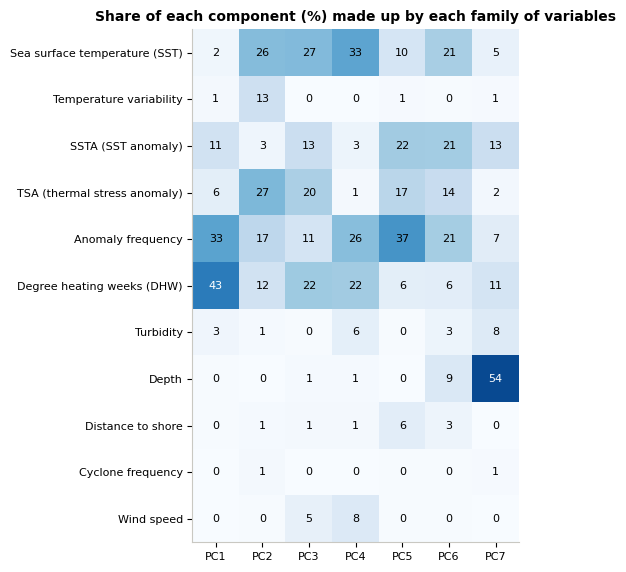

In [11]:
# ---- which environmental families does each component describe? ----
fig, ax = plt.subplots(
    figsize=(1.0 + 0.85 * K_RETAIN, 0.42 * len(fam_contrib) + 1.2)
)
fc = fam_contrib[show]
im = ax.imshow(fc, cmap="Blues", vmin=0, vmax=max(60, fc.to_numpy().max()))
ax.grid(False)
ax.set_xticks(range(K_RETAIN))
ax.set_xticklabels(show)
ax.set_yticks(range(len(fc)))
ax.set_yticklabels(fc.index)
for i in range(fc.shape[0]):
    for j in range(fc.shape[1]):
        v = fc.iloc[i, j]
        ax.text(
            j,
            i,
            f"{v:.0f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if v > 40 else "black",
        )
ax.set_title("Share of each component (%) made up by each family of variables")
plt.tight_layout()
plt.show()

**What the figure shows.** The heatmap gives, for each retained component, the percentage of its total contribution that comes from each family of variables (each column sums to 100). It answers a different question from the loading plots: not which single variable is strongest, but which kind of environmental information the component is made of. Degree heating weeks and anomaly frequency make up most of PC1 (76 %) and nearly half of PC4, and the typical-temperature variables make up just over half of PC2. Non-thermal families (turbidity, depth, distance to shore, cyclones, wind) never contribute more than about 10 % to any of the first five components. This shows that the PCA is dominated by the thermal block, which holds 30 of the 35 variables; the figure describes the structure of the data and is not evidence that temperature is the most important factor for bleaching.


**Text summary.** A printed list of the main families and variables of each component.

In [12]:
# ---- text summary ----
for c in pc_names[:N_INTERPRET]:
    column_loadings = loadings[c].sort_values()
    topf = fam_contrib[c].sort_values(ascending=False).head(3)
    print(
        f"\n{c} ({100*var_ratio[pc_names.index(c)]:.1f}% of variance). Main "
        "families: " + "; ".join(f"{f} {v:.0f}%" for f, v in topf.items())
    )
    print(
        "   highest  :",
        ", ".join(
            f"{n} ({v:+.2f})"
            for n, v in column_loadings.iloc[::-1].head(5).items()
        ),
    )
    print(
        "   lowest   :",
        ", ".join(
            f"{n} ({v:+.2f})" for n, v in column_loadings.head(5).items()
        ),
    )


PC1 (30.0% of variance). Main families: Degree heating weeks (DHW) 43%; Anomaly frequency 33%; SSTA (SST anomaly) 11%
   highest  : SSTA_DHW_Standard_Deviation (+0.94), SSTA_DHWMean (+0.90), SSTA_DHWMax (+0.87), SSTA_FrequencyMean (+0.85), TSA_DHW_Standard_Deviation (+0.82)
   lowest   : SSTA_Minimum (-0.47), TSA_Minimum (-0.42), Temperature_Minimum (-0.31), Distance_to_Shore (-0.19), Depth_m (-0.17)

PC2 (16.8% of variance). Main families: TSA (thermal stress anomaly) 27%; Sea surface temperature (SST) 26%; Anomaly frequency 17%
   highest  : TSA_Mean (+0.91), Temperature_Minimum (+0.88), TSA_Minimum (+0.85), Temperature_Mean (+0.78), TSA_FrequencyMax (+0.56)
   lowest   : Temperature_Kelvin_Standard_Deviation (-0.86), Cyclone_Frequency (-0.25), SSTA_FrequencyMean (-0.24), SSTA_DHWMean (-0.23), Turbidity (-0.22)

PC3 (9.4% of variance). Main families: Sea surface temperature (SST) 27%; Degree heating weeks (DHW) 22%; TSA (thermal stress anomaly) 20%
   highest  : Temperature_Kelvin (

## Step 5 · Association of the components with bleaching severity

**Method.** The component scores were compared between the three bleaching groups. With about 23,000 samples even trivial differences give very small p-values, so the comparison was judged mainly on **effect size**:
- **Cliff's δ = 2·AUC − 1**, where the AUC is the probability that a randomly chosen High sample has a higher component score than a randomly chosen Low sample (0.5 means no separation). δ runs from −1 to +1 and is rank-based, so it is robust to skewed scores and outliers. The conventional guide is |δ| < 0.15 negligible, 0.15 to 0.33 small, 0.33 to 0.47 medium and above 0.47 large. δ was the headline measure because Step 9 uses the same rank statistic to control for data source;
- **Cohen's d**: the difference between the High and Low means divided by the pooled standard deviation (0.2 small, 0.5 medium, 0.8 large). It is the parametric counterpart of δ and assumes roughly symmetric distributions of similar spread, so it was reported next to δ as a check (Step 6 gives it with a confidence interval and an adjusted p-value);
- **Spearman ρ** between the score and the continuous bleaching percentage, which describes the gradient across the groups;
- **Kernel density estimates (KDE)** of the scores of each group. Each curve integrates to 1, so the unequal group sizes do not affect the comparison.

Medians and rank-based statistics were used because the groups are unbalanced and the scores are not normally distributed.

**Results.**
- **The two largest components barely separated the groups.** PC1 (30 % of the variance) had a negligible effect (δ = +0.03, with the Moderate group lowest rather than a steady rise) and PC2 (17 %) a small one (δ = −0.16). Together they cover 47 % of the environmental variation, yet in the PC1–PC2 plot the three groups lie almost on top of each other. **The largest patterns of environmental variation are not the patterns that matter most for bleaching.**
- **PC3 and PC4 separated the groups with a medium effect**: δ = +0.44 and +0.47 and AUC ≈ 0.72 to 0.74, i.e. a randomly chosen High sample scored higher than a randomly chosen Low sample about 72 to 74 % of the time. For both components the median rose steadily from Low to Moderate to High (PC3: −0.32, 0.75, 0.97; PC4: −0.21, 0.35, 1.25).
- **Cohen's d led to the same conclusion**: d = 0.82 for PC3 and 0.86 for PC4 (large), −0.22 for PC2 and −0.27 for PC5 (small) and 0.05 for PC1 (negligible). For PC3 and PC4 the AUC implied by d under normality (about 0.72 to 0.73) matches the observed AUC (0.72 to 0.74), so the result does not depend on the shape of the score distributions. The two measures differ most for PC5 (d = −0.27 against δ = −0.11), where the mean difference is more sensitive to the shape of the distribution than the rank-based δ.
- **The density curves show the same pattern.** The curves of PC3 and PC4 shift to the right from Low through Moderate to High but overlap heavily, whereas the curves of PC1 and PC2 have several peaks and their medians do not rise steadily with severity.
- Higher scores on PC3 and PC4 correspond to more heat stress at the time of the survey and over the preceding year (Step 4). Together they hold only 17 % of the variance.
- The separation was a **gradient with heavy overlap**, not a set of distinct clusters: in the PC3–PC4 plot the High group lies towards the upper right but is mixed with Low and Moderate samples. The correlation between each score and the continuous bleaching percentage was modest (Spearman ρ = 0.32 for PC3 and 0.22 for PC4), so the environment alone does not determine the bleaching level.


**Group comparison table.** The effect sizes (Cliff's δ and Cohen's d) and the Spearman correlation of every retained component, with the medians of each group.

In [13]:
# Step 5 · Compare Low, Moderate and High bleaching on the components
group_labels = df[GROUP_COL].to_numpy().astype(str)
effect_d = welch_high_low(
    {c: scores[c].to_numpy() for c in pc_names[:K_RETAIN]},
    group_labels,
).cohens_d
rows = []
for c in pc_names[:K_RETAIN]:
    x = scores[c].to_numpy()
    auc = auc_high_low(x, group_labels)
    rows.append(
        {
            "component": c,
            "variance_%": 100 * var_ratio[pc_names.index(c)],
            **{
                f"median_{k}": np.median(x[group_labels == k])
                for k in GROUP_ORDER
            },
            "cliffs_delta": 2 * auc - 1,
            "cohens_d": effect_d[c],
            "spearman_with_bleaching_%": stats.spearmanr(
                x, df[TARGET]
            ).statistic,
        }
    )
group_table = pd.DataFrame(rows).set_index("component")
group_table["strength"] = pd.cut(
    group_table.cliffs_delta.abs(),
    [-1, 0.147, 0.33, 0.474, 1],
    labels=["negligible", "small", "medium", "large"],
)
display(group_table)
best = group_table.cliffs_delta.abs().sort_values(ascending=False)
print(
    "Components ranked by how strongly they separate High from Low bleaching:"
)
print(
    "   "
    + ", ".join(
        f"{c} (δ={group_table.cliffs_delta[c]:+.2f})" for c in best.index[:5]
    )
)

,variance_%,median_Low,median_Moderate,median_High,cliffs_delta,cohens_d,spearman_with_bleaching_%,strength
component,,,,,,,,
PC1,29.96,0.1167,-0.8479,0.351,0.02852,0.0549,-0.1347,negligible
PC2,16.76,0.6667,-0.4075,0.09252,-0.1552,-0.2189,-0.1942,small
PC3,9.43,-0.3223,0.7476,0.9685,0.4395,0.8163,0.318,medium
PC4,7.208,-0.2079,0.3507,1.249,0.4712,0.8627,0.216,medium
PC5,5.675,0.1753,-0.2233,0.01772,-0.1076,-0.2679,-0.2225,negligible
PC6,3.858,0.05725,-0.09827,-0.2564,-0.1697,-0.291,-0.092,small
PC7,2.995,-0.02678,0.182,-0.1476,-0.01053,0.03966,0.08042,negligible


Components ranked by how strongly they separate High from Low bleaching:
   PC4 (δ=+0.47), PC3 (δ=+0.44), PC6 (δ=-0.17), PC2 (δ=-0.16), PC5 (δ=-0.11)


**Score plots.** The samples plotted on pairs of components and coloured by bleaching group.

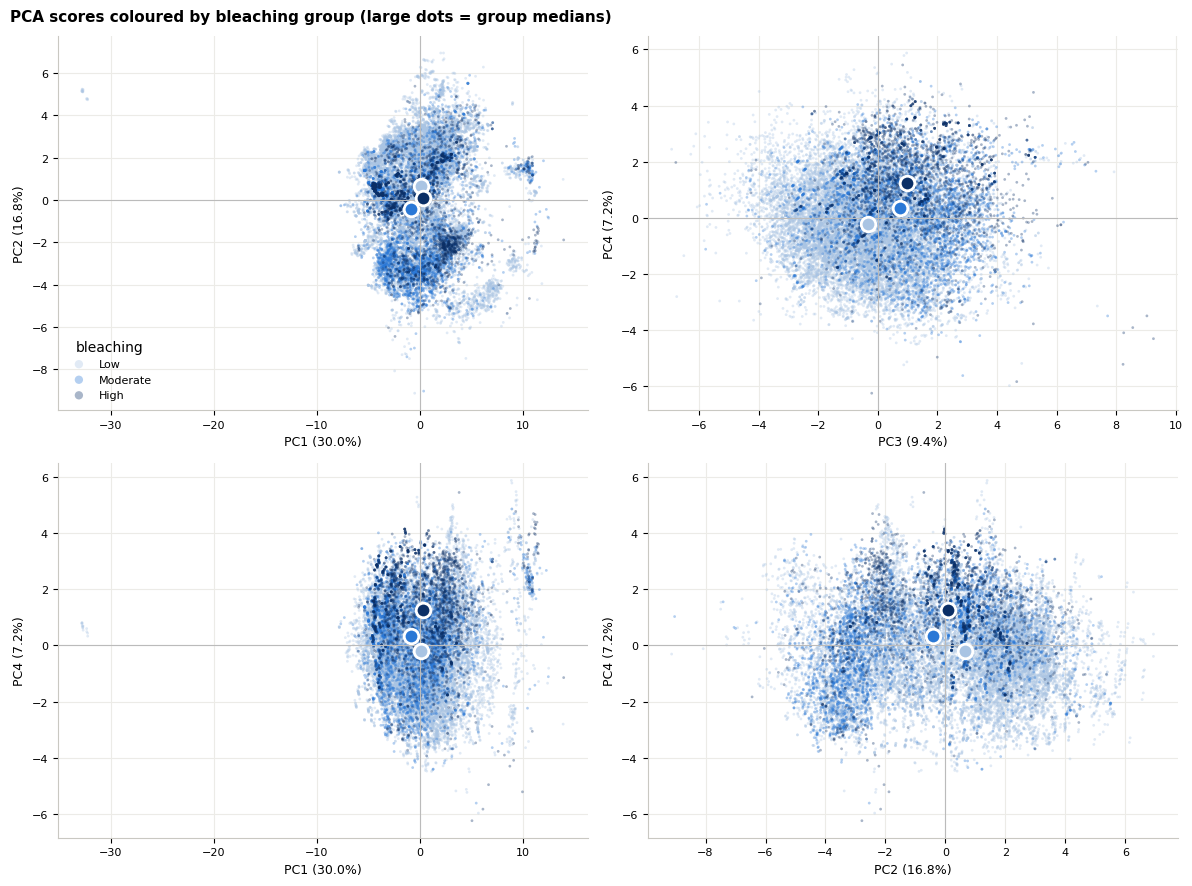

In [14]:
# ---- score plots coloured by bleaching group ----
top2 = sorted(
    group_table.cliffs_delta.abs().sort_values(ascending=False).index[:2],
    key=lambda c: int(c[2:]),
)  # the two best-separating components
best1 = group_table.cliffs_delta.abs().idxmax()
pairs = [("PC1", "PC2"), (top2[0], top2[1]), ("PC1", best1), ("PC2", best1)]
pairs = [
    pr for i, pr in enumerate(pairs) if pr[0] != pr[1] and pr not in pairs[:i]
]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()
for ax, (a, b) in zip(axes, pairs):
    for (
        k
    ) in (
        GROUP_ORDER
    ):  # Low drawn first, High last so the rarer samples stay visible
        m = group_labels == k
        ax.scatter(
            scores.loc[m, a],
            scores.loc[m, b],
            s=4,
            alpha=0.35,
            color=GROUP_COLORS[k],
            edgecolors="none",
            label=k,
        )
    for k in GROUP_ORDER:
        m = group_labels == k
        ax.scatter(
            scores.loc[m, a].median(),
            scores.loc[m, b].median(),
            s=110,
            color=GROUP_COLORS[k],
            edgecolors="white",
            linewidths=2,
            zorder=5,
        )
    ax.set_xlabel(f"{a} ({100*var_ratio[int(a[2:])-1]:.1f}%)")
    ax.set_ylabel(f"{b} ({100*var_ratio[int(b[2:])-1]:.1f}%)")
    ax.axhline(0, color="#bbb", lw=0.8)
    ax.axvline(0, color="#bbb", lw=0.8)
first_unused = len(pairs)
for ax in axes[first_unused:]:
    ax.set_visible(False)
axes[0].legend(markerscale=3, title="bleaching", loc="best")
fig.suptitle(
    "PCA scores coloured by bleaching group (large dots = group medians)",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
plt.tight_layout()
plt.show()

**What the figure shows.** Each point is one sample placed by its scores on two components, coloured by bleaching group (light = Low, mid = Moderate, dark = High), and the large dots are the group medians. The panels pair PC1 with PC2, PC3 with PC4, and each of PC1 and PC2 with PC4. *PC1 vs PC2:* the three medians lie close together near the origin and are not ordered by severity (the Moderate median is lowest on PC2 and the Low median highest), so these two components, which carry long-term climate and geography, do not separate the groups; the cloud is structured into regional clusters rather than by bleaching. *PC3 vs PC4 and the PC4 panels:* the medians move in order from Low to Moderate to High, towards higher PC3 and especially higher PC4, and in the PC1 and PC2 panels the medians are stacked along the PC4 axis but barely move along PC1 or PC2. The shift is a shift of the centre of each group: the point clouds overlap heavily, so a sample's position does not identify its bleaching group. The plot is a visual check only (the points are strongly overplotted and High samples are a minority); the effect sizes and tests below give the quantitative evidence. A small set of samples far out on PC1 (near −32) and a cluster near +10 to +12 do not affect the medians.


**Score densities.** Kernel density estimate (KDE) of each interpreted component within each bleaching group. Each curve integrates to 1; dashed lines mark the group medians; the titles give Cohen's d and Cliff's δ.

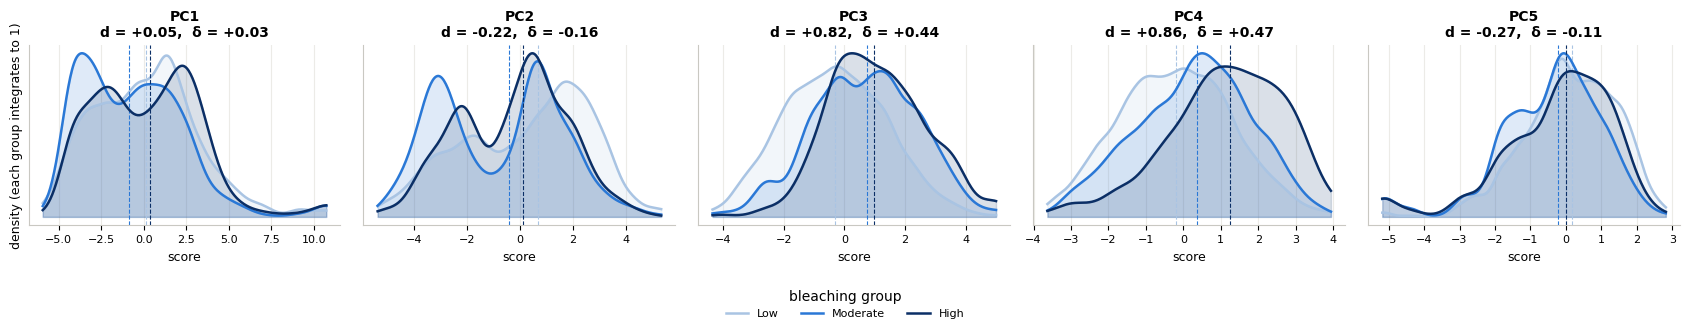

In [15]:
# ---- score densities (KDE) by bleaching group ----
fig, axes = plt.subplots(1, N_INTERPRET, figsize=(3.4 * N_INTERPRET, 3.3))
for ax, c in zip(axes, pc_names[:N_INTERPRET]):
    low, high = np.percentile(scores[c], [0.5, 99.5])
    grid = np.linspace(low, high, 300)
    for k in GROUP_ORDER:
        values = scores.loc[group_labels == k, c].to_numpy()
        density = stats.gaussian_kde(values)(grid)
        ax.plot(grid, density, color=GROUP_COLORS[k], lw=1.8, label=k)
        ax.fill_between(grid, density, color=GROUP_COLORS[k], alpha=0.15)
        ax.axvline(np.median(values), color=GROUP_COLORS[k], lw=0.8, ls="--")
    ax.set_title(
        f"{c}\nd = {group_table.cohens_d[c]:+.2f},"
        f"  δ = {group_table.cliffs_delta[c]:+.2f}"
    )
    ax.set_xlabel("score")
    ax.set_yticks([])
axes[0].set_ylabel("density (each group integrates to 1)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, title="bleaching group", loc="lower center", ncol=3
)
plt.tight_layout(rect=(0, 0.14, 1, 1))
plt.show()

**What the figure shows.** Each panel is the distribution (kernel density) of the scores of one component, drawn separately for the Low, Moderate and High groups; dashed lines mark the group medians, and the panel title gives Cohen's d and Cliff's δ for High versus Low. For PC1 the three curves nearly coincide (d = +0.06, δ = +0.03), and for PC2 and PC5 the shift is small and in the negative direction (d = −0.22 and −0.27). For PC3 (d = +0.82, δ = +0.44) and PC4 (d = +0.86, δ = +0.47) the High curve is clearly displaced to the right of the Low curve, with the Moderate curve in between. The curves still overlap over most of their range: bleaching is associated with a shift in the distribution of these components, not with a separate range of values. This view shows what a medium effect size looks like and that the shift is a gradual, ordered one across the three groups.


**Components ranked by separation.** Cliff's δ of every retained component as a bar chart.

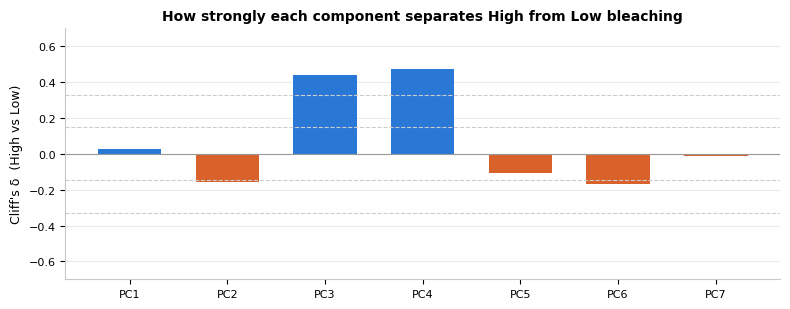

In [16]:
# ---- which components separate the groups? ----
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(
    group_table.index,
    group_table.cliffs_delta,
    color=[C_POS if v > 0 else C_NEG for v in group_table.cliffs_delta],
    width=0.65,
)
for y in (-0.33, -0.147, 0.147, 0.33):
    ax.axhline(y, color="#ccc", lw=0.8, ls="--")
ax.axhline(0, color="#999", lw=0.8)
ax.set_ylabel("Cliff's δ  (High vs Low)")
ax.set_ylim(-0.7, 0.7)
ax.set_title("How strongly each component separates High from Low bleaching")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What the figure shows.** Cliff's δ (High versus Low) of each retained component as a bar, with dashed reference lines at ±0.147, ±0.33 that mark the boundaries between negligible, small, medium and large effects. Two components pass the medium threshold: PC3 (δ = +0.44) and PC4 (δ = +0.47), both positive, i.e. High samples tend to have higher scores. PC2 (−0.16) and PC6 (−0.17) are small and negative, and PC1 (+0.03), PC5 (−0.11) and PC7 (−0.01) are negligible. PC1, the component with the most variance, is therefore not the one most related to bleaching; the variance a component explains and its association with the outcome are different things, and the relevant information lies in the third and fourth components.


## Step 6 · Information about bleaching retained by the components

**Method.** To quantify how much of the High-versus-Low difference is retained after the dimension reduction, only statistical tests were used (no predictive model). Samples with High bleaching were compared with samples with Low bleaching as follows:
- a **Welch t-test** (which does not assume equal variances) on each retained component and, for comparison, on each original variable, reported with the mean difference, its 95 % confidence interval and Cohen's d (based on the sample-size-weighted pooled standard deviation);
- **Benjamini–Hochberg false-discovery-rate (BH-FDR)** adjustment of the p-values within each family of tests, so that testing many components or variables does not create false findings; a q-value below 0.05 was counted as significant;
- a **site-level repeat** of the Welch test on site means (the High samples of a site averaged and compared with the averaged Low samples of a site), because samples from the same site are not independent;
- **Hotelling's T² test** on all retained components together. Its squared Mahalanobis distance D² is a multivariate effect size, and the ratio D²(retained components) / D²(all variables) is the share of the High-versus-Low separation retained by the components. Because the PCA is a rotation of the variables, D² for all components equals D² for all variables.

With this many samples nearly every p-value is very small, so the effect sizes and confidence intervals, not only the q-values, were used to judge the results.

**Results.**
- **PC3 and PC4 carry the bleaching signal.** High-bleaching samples scored about 1.4 higher on PC3 (95 % CI 1.34 to 1.49) and 1.3 higher on PC4 (1.26 to 1.40); Cohen's d = 0.82 and 0.86 (large). Both remained significant after BH-FDR (q < 10⁻²⁴⁰) and on site means (d ≈ 0.80 and 0.85), so they are not an artefact of many samples per site.
- **The other components differed only slightly.** PC2, PC5 and PC6 were statistically significant but small (|d| = 0.22 to 0.29), and PC1 and PC7 were negligible (d = 0.05 and 0.04; PC1 had q = 0.017 and PC7 was not significant, q = 0.11). On site means PC5 was no longer significant (q = 0.24), so its difference rests on repeated samples within sites. The first two components alone retained only about **1 %** of the High-versus-Low separation (D² = 0.05 against 3.7 for all variables).
- **The seven retained components retained about half of the multivariate separation** (D² = 1.85 of 3.67, i.e. 50 %; Hotelling F = 511, p < 10⁻³⁰⁰). Compressing 35 variables to 7 components therefore loses a good part of the High-versus-Low difference, and the PCA does not concentrate that difference in the leading components.
- **No component exceeded the best single variable.** The strongest original variable, `TSA_DHW`, had |d| = 1.21, against 0.86 for the best component. 32 of the 35 variables differed between High and Low at q < 0.05 (26 of 35 on site means), which is expected with many correlated variables; the effect sizes matter more than significance.
- These tests pool the samples of all data sources; Step 9 repeats the comparison within each source.


Welch t-test on each retained component (High minus Low):


,difference,ci95_low,ci95_high,cohens_d,p,q_bh,site_level_d,site_level_q_bh
variable,,,,,,,,
PC1,0.1784,0.03492,0.3219,0.0549,0.01483,0.0173,0.2072,1.473e-13
PC2,-0.5254,-0.6183,-0.4325,-0.2189,4.629e-28,8.1e-28,-0.1346,6.391e-08
PC3,1.417,1.342,1.492,0.8163,1.271e-245,8.899e-245,0.8012,5.263e-169
PC4,1.326,1.256,1.397,0.8627,2.516e-241,8.807e-241,0.8537,1.8e-162
PC5,-0.3668,-0.4366,-0.2971,-0.2679,1.777e-24,2.487e-24,-0.03308,0.2414
PC6,-0.3381,-0.39,-0.2862,-0.291,2.262e-36,5.278e-36,-0.1501,9.033e-08
PC7,0.04022,-0.009033,0.08947,0.03966,0.1094,0.1094,-0.2529,1.784e-17


Original variables: 32 of 35 differ between High and Low at q < 0.05 (all samples); 26 of 35 on site means.
Largest |Cohen's d| among the original variables:


,|d|
variable,
TSA_DHW,1.212
SSTA_DHW,0.9277
TSA_Frequency,0.8021
SSTA_Frequency,0.7286
SSTA_Standard_Deviation,0.6473


,n_features,mahalanobis_sq,F,df1,df2,p,share_of_all_variables_D2
inputs,,,,,,,
PC1–PC2,2,0.05034,48.56,2,19080,9.195e-22,0.0137
PC1–PC7 (retained),7,1.854,511,7,19075,0,0.5047
all 35 original variables,35,3.674,202.2,35,19047,0,1


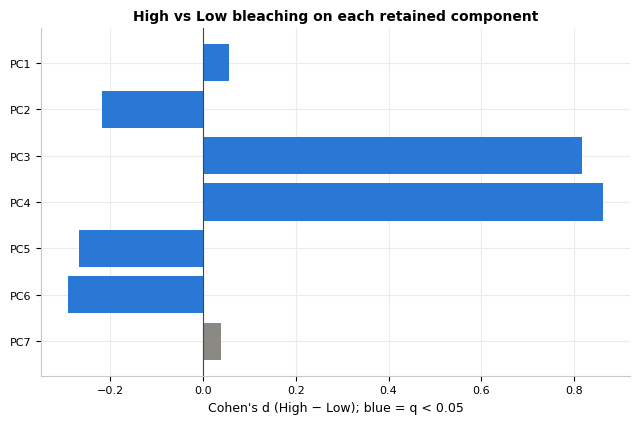

In [17]:
# Step 6 · How much bleaching information do the components keep?
site_labels = df[SITE].to_numpy()
retained = pc_names[:K_RETAIN]

# (a) Welch t-test per retained component (High vs Low), BH-FDR
component_tests = welch_high_low(
    {pc: scores[pc].to_numpy() for pc in retained}, group_labels, site_labels
)
shown = ["difference", "ci95_low", "ci95_high", "cohens_d", "p", "q_bh"]
print("Welch t-test on each retained component (High minus Low):")
display(component_tests[shown + ["site_level_d", "site_level_q_bh"]])

# (b) the same test for every original variable, BH-FDR across variables
variable_tests = welch_high_low(
    {v: X[v].to_numpy() for v in features}, group_labels, site_labels
)
n_vars = len(variable_tests)
print(
    f"Original variables: {(variable_tests.q_bh < 0.05).sum()} of {n_vars} "
    "differ between High and Low at q < 0.05 (all samples); "
    f"{(variable_tests.site_level_q_bh < 0.05).sum()} of {n_vars} on site "
    "means."
)
print("Largest |Cohen's d| among the original variables:")
display(
    variable_tests.cohens_d.abs()
    .sort_values(ascending=False)
    .head(5)
    .to_frame("|d|")
)

# (c) Hotelling T2 on all components at once; share of separation kept
is_high, is_low = group_labels == "High", group_labels == "Low"
matrices = {
    "PC1–PC2": scores[pc_names[:2]].to_numpy(),
    f"PC1–PC{K_RETAIN} (retained)": scores[retained].to_numpy(),
    f"all {len(features)} original variables": X.to_numpy(),
}
rows = []
for name, matrix in matrices.items():
    result = hotelling_two_sample(matrix[is_high], matrix[is_low])
    rows.append({"inputs": name, "n_features": matrix.shape[1], **result})
hotelling = pd.DataFrame(rows).set_index("inputs")
hotelling["share_of_all_variables_D2"] = (
    hotelling.mahalanobis_sq / hotelling.mahalanobis_sq.iloc[-1]
)
display(hotelling)

fig, ax = plt.subplots(figsize=(6.5, 0.45 * len(retained) + 1.2))
colours = [
    C_POS if q < 0.05 else C_MUTED for q in component_tests.q_bh.to_numpy()
]
ax.barh(
    retained[::-1],
    component_tests.cohens_d.to_numpy()[::-1],
    color=colours[::-1],
)
ax.axvline(0, color="#444", lw=0.8)
ax.set_xlabel("Cohen's d (High − Low); blue = q < 0.05")
ax.set_title("High vs Low bleaching on each retained component")
plt.tight_layout()
plt.show()

**What the figure shows.** The bars are Cohen's d (High minus Low) of each retained component from the Welch t-test; blue bars have a BH-FDR q-value below 0.05 and grey bars do not. The two largest effects are PC4 (d = +0.86) and PC3 (d = +0.82), which are large by the usual convention for d; PC6, PC5 and PC2 are small (d = −0.29, −0.27 and −0.22), and PC1 (+0.06) is negligible, although it is statistically significant (q = 0.017) because of the large sample. PC7 is the only component that is not significant (q = 0.11). The figure illustrates why the effect size and not the p-value should be used to rank the components: with more than 19,000 samples almost every component is significant, but only PC3 and PC4 differ by a substantial amount. The same two components remain at d ≈ 0.80–0.85 when the test is repeated on site means.


## Step 7 · Preparation of the categorical interpretation

**Method.** The categorical columns were excluded from the PCA and are used here only to interpret it. Missing categories were labelled `Unknown`, the categorical features analysed in the next steps were selected (data source, ocean, realm, country, ecoregion and exposure; high-cardinality labels such as site name and reef identifier remain in the file but are not analysed), and a summary table of the data sources was built (samples, sites, share of High and Low samples, median bleaching and period covered). The PCA of all samples (`full_load`) was refitted as the reference solution for Step 10.

**Results.** The data sources differed strongly in size and in how much bleaching they report, so they cannot be pooled naively:
- Reef Check (11,249 samples) and AGRRA (2,847) contained almost no High samples (111 and 0, i.e. about 1 % and 0 %).
- Donner (5,618 samples) reported bleaching most often: 30.5 % of its samples were High. **Donner supplied 1,715 of the 2,178 High samples (79 %).**
- FRRP, Kumagai and McClanahan supplied 122, 77 and 131 High samples. Safaie and the two smallest sources contributed too few samples to be analysed separately.

The pooled High-versus-Low comparisons are therefore partly comparisons between data sources, which motivates the within-source analysis of Step 9.


In [18]:
# Step 7 · Categorical columns used to interpret the components
CAT_COLS = [c for c in meta.get("categorical_columns", []) if c in df.columns]
for c in CAT_COLS:
    df[c] = df[c].fillna("Unknown").astype(str)
# the categorical features used for the interpretation (high-cardinality
# labels such as Site_Name / Reef_ID are kept in the file but not analysed
# here)
ANALYSE = [
    c
    for c in [
        "Data_Source",
        "Ocean_Name",
        "Realm_Name",
        "Country_Name",
        "Ecoregion_Name",
        "Exposure",
    ]
    if c in CAT_COLS
]
group_labels = df[GROUP_COL].to_numpy().astype(str)
df["Depth_imputed"] = df[FLAG_IMPUTED].astype(int)

source_table = (
    df.groupby("Data_Source")
    .agg(
        samples=(SAMPLE, "size"),
        sites=(SITE, "nunique"),
        pct_high=(GROUP_COL, lambda s: 100 * (s.astype(str) == "High").mean()),
        pct_low=(GROUP_COL, lambda s: 100 * (s.astype(str) == "Low").mean()),
        median_bleaching=(TARGET, "median"),
        mean_bleaching=(TARGET, "mean"),
        pct_depth_imputed=("Depth_imputed", lambda s: 100 * s.mean()),
        first_year=(YEAR, "min"),
        last_year=(YEAR, "max"),
    )
    .sort_values("samples", ascending=False)
)
source_table["n_high"] = (
    df[group_labels == "High"]
    .groupby("Data_Source")
    .size()
    .reindex(source_table.index)
    .fillna(0)
    .astype(int)
)
source_table["n_low"] = (
    df[group_labels == "Low"]
    .groupby("Data_Source")
    .size()
    .reindex(source_table.index)
    .fillna(0)
    .astype(int)
)
large_sources = source_table.index[:4].tolist()

# reference solution on all samples (used by Step 10)
full_load, full_var = fit_loadings(X, N_INTERPRET, RANDOM_STATE)

## Step 8 · Relation of the components to the categorical features

**Method.** For each categorical feature and each component, **ω²** is the share of the component's variance that differs *between* the categories. It is a bias-corrected version of η², so that features with many levels are not favoured by chance; categories with fewer than 50 samples were pooled into "Other". The last row of the table is the reference: the share explained by the **bleaching group**, the quantity the analysis tries to explain.

**Results.**
- **The largest components were geographic.** Country and ecoregion explained 48 % and 48 % of PC1 and 75 % and 80 % of PC2 (and about 50 % of PC5), and realm and ocean explained 29 % and 22 % of PC1. These components describe *where* a site is (its long-term climate), in agreement with the reading of the loadings in Step 4.
- **The bleaching group explained very little of any component** (at most 8 % of PC3 and 6 % of PC4, and under 3 % of the rest). The component most tied to bleaching is not the one most tied to geography.
- **Data source explained a moderate share of several components** (29 % of PC2, 14 % of PC3, 13 % of PC5, 12 % of PC4 and 9 % of PC1). For PC3 and PC4 the data source explained *more* of the variance than the bleaching group, so part of the PC3 and PC4 pattern is a source effect; Step 9 measures how much.
- **Exposure explained little** (at most 10 % of PC1, 7 % of PC5, 2 % of PC3 and under 1 % of PC4), so it is not a major environmental axis in this dataset.
- Country and ecoregion have many levels and partly coincide with data source (a source often works in a few regions); ω² corrects for the number of levels but cannot separate these overlaps.


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Data_Source,8.8,29.4,13.9,11.6,12.8,3.5,4.9
Ocean_Name,22.4,6,3.9,4.3,12.7,2.3,4.9
Realm_Name,28.8,14.7,4.9,5,12.4,8.1,7.1
Country_Name,48,74.7,24.2,34.1,49.8,21.6,23.6
Ecoregion_Name,48,79.5,20.5,40.5,47.8,20,21.8
Exposure,10,4.2,2,0.6,7.1,0.6,6.2
Bleaching_Group (reference),0.8,2.7,8.2,6.4,2.7,0.9,0.9


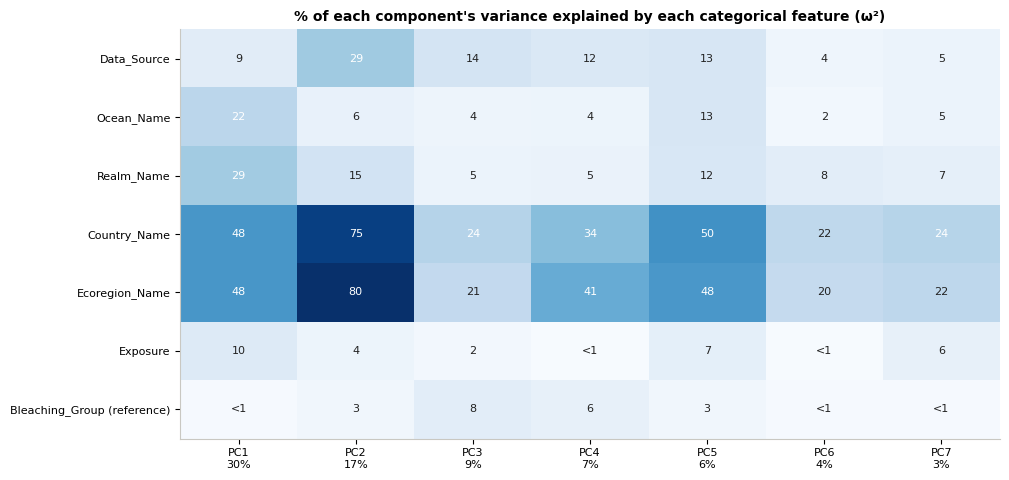

In [19]:
# Step 8 · How much of each component is explained by each categorical
# feature?
PCS = pc_names[:K_RETAIN]
omega2_table = pd.DataFrame(
    {
        pc: [100 * omega_squared(scores[pc], df[cat]) for cat in ANALYSE]
        + [100 * omega_squared(scores[pc], df[GROUP_COL])]
        for pc in PCS
    },
    index=ANALYSE + ["Bleaching_Group (reference)"],
)
display(omega2_table.round(1))

fig, ax = plt.subplots(
    figsize=(1.0 * len(PCS) + 3.2, 0.5 * len(omega2_table) + 1.4)
)
im = ax.imshow(
    omega2_table.to_numpy(),
    cmap="Blues",
    vmin=0,
    vmax=max(40, omega2_table.to_numpy().max()),
    aspect="auto",
)
ax.set_xticks(range(len(PCS)))
ax.set_xticklabels(
    [f"{c}\n{100*var_ratio[i]:.0f}%" for i, c in enumerate(PCS)]
)
ax.set_yticks(range(len(omega2_table)))
ax.set_yticklabels(omega2_table.index)
ax.grid(False)
for i in range(omega2_table.shape[0]):
    for j in range(omega2_table.shape[1]):
        v = omega2_table.iat[i, j]
        ax.text(
            j,
            i,
            f"{v:.0f}" if v >= 1 else "<1",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if v > 22 else "#222",
        )
ax.set_title(
    "% of each component's variance explained by each categorical feature (ω²)"
)
plt.tight_layout()
plt.show()

**What the figure shows.** The heatmap gives the percentage of each retained component's variance explained by each categorical feature (ω², corrected for the number of categories); the bottom row, bleaching group, is the reference. Country and ecoregion explain the most: 75 % and 80 % of PC2, about 48–50 % of PC1 and PC5, and 34 % and 41 % of PC4. The data source explains 29 % of PC2. This shows that PC1, PC2 and PC5 largely encode where a reef is (its region and the data source that surveyed it). In contrast, bleaching group explains only 8.2 % of PC3 and 6.4 % of PC4 and under 3 % of the other components; PC3 and PC4 are the components most related to bleaching and also the ones that are least tied to a location (country explains 24 % of PC3). The figure shows both what the components represent and why the pooled analysis has to be checked within data sources (next step).


## Step 9 · Control for data source: separation within each source

**Method.** A pooled association between a component and bleaching can arise only because the sources that report more bleaching also sit in different environments. To remove this, the High-versus-Low comparison of Step 5 (Cliff's δ) was repeated **inside each data source** and the within-source values were then combined into one **source-adjusted δ**, in which each source is weighted by its number of High × Low sample pairs (the stratified version of the AUC). Only sources with at least 30 High and 30 Low samples were analysed.

**Results.**
- **The heat-stress finding survived the control, but weaker.** Within every one of the four large sources (Reef Check, Donner, FRRP and Kumagai), High samples scored higher than Low samples on **both PC3 and PC4**: PC3 δ = 0.40, 0.22, 0.63 and 0.79, and PC4 δ = 0.44, 0.31, 0.55 and 0.42 respectively. The medians rose from Low to Moderate to High in each source.
- **The source-adjusted δ was 0.28 for PC3 and 0.35 for PC4**, compared with 0.44 and 0.47 pooled. About a third of the pooled PC3 effect and a quarter of the PC4 effect therefore came from differences between sources. What remains is a **small-to-medium** effect, and the weakest source (Donner, which holds most of the High samples) has the smallest effect.
- **The large components remained unrelated to bleaching**: the adjusted δ was +0.12 for PC1, −0.06 for PC2 and +0.09 for PC5. Their pooled values (+0.03, −0.16 and −0.11) changed sign or size with source, so they are not reliably related to bleaching.
- The sources differ in their *baseline* on PC3 (for example the Low group of Kumagai lies near −1.6 while the Low group of FRRP lies near +0.8), so raw scores are not comparable between sources. Within-source comparisons are therefore the fair test.


**Within-source table.** Cliff's δ of every component within each source, together with the pooled and source-adjusted values.

In [20]:
# Step 9 · Does the High-vs-Low separation hold within each data source?
comp_cols = {c: scores[c].to_numpy() for c in pc_names[:N_INTERPRET]}
pooled = {c: group_table.cliffs_delta[c] for c in comp_cols}
within_source_pc, source_adjusted_pc = within_stratum_delta(
    df, group_labels, "Data_Source", comp_cols
)
pc_delta_table = pd.concat(
    [
        within_source_pc,
        pd.DataFrame([pooled], index=["POOLED (all samples)"]),
        pd.DataFrame([source_adjusted_pc], index=["SOURCE-ADJUSTED"]),
    ]
)
display(pc_delta_table)
print(
    "Sources with ≥30 High and ≥30 Low samples: "
    f"{list(within_source_pc.index)}  "
    f"({int(within_source_pc.n_high.sum()):,} of "
    f"{int((group_labels == 'High').sum()):,} High samples)"
)

,n_high,n_low,PC1,PC2,PC3,PC4,PC5
Reef_Check,111,1.059e+04,-0.04876,-0.08618,0.4029,0.437,-0.06027
Donner,"1,715","2,110",0.1646,-0.04895,0.2203,0.3112,0.1398
FRRP,122,"1,180",0.3427,-0.1235,0.6302,0.5509,0.05168
Kumagai,77,409,0.1198,0.3203,0.7906,0.4171,0.2215
POOLED (all samples),NaN,NaN,0.02852,-0.1552,0.4395,0.4712,-0.1076
SOURCE-ADJUSTED,NaN,NaN,0.119,-0.05758,0.279,0.3486,0.0904


Sources with ≥30 High and ≥30 Low samples: ['Reef_Check', 'Donner', 'FRRP', 'Kumagai']  (2,025 of 2,178 High samples)


**Heatmap of within-source δ.** The same values as a heatmap, with the number of High and Low samples of each source.

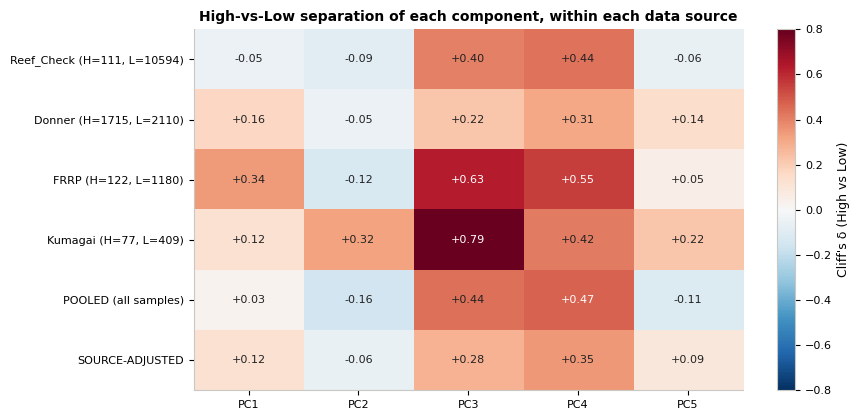

In [21]:
fig, ax = plt.subplots(
    figsize=(1.2 * N_INTERPRET + 3, 0.5 * len(pc_delta_table) + 1.3)
)
M = pc_delta_table[list(comp_cols)].to_numpy(float)
im = ax.imshow(M, cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(comp_cols)))
ax.set_xticklabels(list(comp_cols))
ax.set_yticks(range(len(pc_delta_table)))
ax.set_yticklabels(
    [
        (
            f"{i} (H={int(r.n_high)}, L={int(r.n_low)})"
            if i in within_source_pc.index
            else i
        )
        for i, r in pc_delta_table.fillna(0).iterrows()
    ]
)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(
            j,
            i,
            f"{M[i, j]:+.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(M[i, j]) > 0.45 else "#222",
        )
fig.colorbar(im, ax=ax, label="Cliff's δ (High vs Low)")
ax.set_title(
    "High-vs-Low separation of each component, within each data source"
)
plt.tight_layout()
plt.show()

**What the figure shows.** The heatmap gives Cliff's δ (High versus Low) of each of the first five components computed inside each data source, with the pooled value and the source-adjusted value in the bottom rows (red = High scores higher, blue = lower). The columns PC3 and PC4 are red in every source (δ = 0.40, 0.22, 0.63 and 0.79 on PC3 and 0.44, 0.31, 0.55 and 0.42 on PC4, for Reef Check, Donner, FRRP and Kumagai), so the heat-stress pattern is not produced by one source. PC1, PC2 and PC5 change sign or stay near zero from source to source. The source-adjusted values (PC3 0.28, PC4 0.35) are lower than the pooled values (0.44 and 0.47), showing that part of the pooled effect came from differences between sources. The weakest within-source effect is in Donner, which holds most of the High samples, so the conclusion is of a consistent but small-to-medium association, not a large one.


**Distributions inside each source.** PC3 and PC4 by bleaching group within each large source.

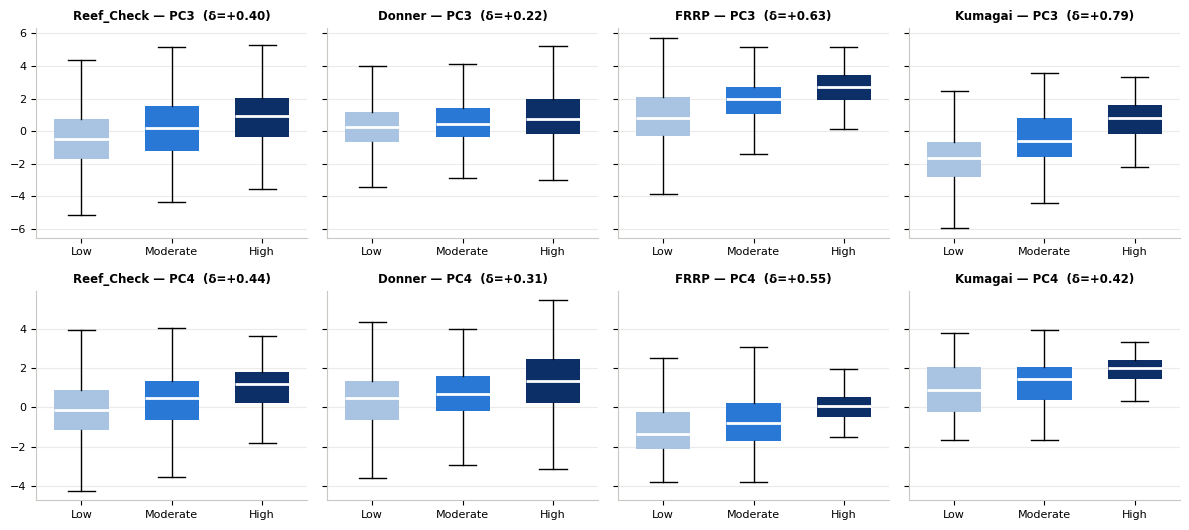

In [22]:
# ---- distributions of PC3 / PC4 by bleaching group inside each source ----
fig, axes = plt.subplots(
    2,
    len(within_source_pc),
    figsize=(3.0 * len(within_source_pc), 5.4),
    sharey="row",
    squeeze=False,
)
for j, s in enumerate(within_source_pc.index):
    for i, c in enumerate(["PC3", "PC4"]):
        data = [
            scores.loc[(df.Data_Source == s) & (group_labels == k), c]
            for k in GROUP_ORDER
        ]
        bp = axes[i, j].boxplot(
            data,
            widths=0.6,
            showfliers=False,
            patch_artist=True,
            medianprops=dict(color="white", lw=2),
        )
        for patch, k in zip(bp["boxes"], GROUP_ORDER):
            patch.set_facecolor(GROUP_COLORS[k])
            patch.set_edgecolor("none")
        axes[i, j].set_xticks(range(1, 4))
        axes[i, j].set_xticklabels(GROUP_ORDER)
        axes[i, j].grid(axis="x", visible=False)
        axes[i, j].set_title(
            f"{s} — {c}  (δ={within_source_pc.loc[s, c]:+.2f})", fontsize=8.5
        )
plt.tight_layout()
plt.show()

**What the figure shows.** For each of the four large sources, box plots of the PC3 scores (top row) and PC4 scores (bottom row) in the Low, Moderate and High groups (outliers not drawn; the white line is the median), with the within-source δ in the panel title. In every source the boxes move upwards from Low to Moderate to High, but the boxes of neighbouring groups overlap. The shift is largest in Kumagai and FRRP on PC3 and in FRRP on PC4, and smallest in Donner. The figure shows the raw distributions behind the heatmap of the previous figure: the association with heat stress is visible inside each source without pooling, which supports using PC3 and PC4 as the heat-stress components, while the overlap shows that the components describe tendencies and do not classify individual samples.


## Step 10 · Stability of the PCA structure across data sources

**Method.** The PCA was refitted separately on each large data source (at least 800 samples), and the loadings of each fit were compared with the loadings of the full-data PCA using the **congruence coefficient** (1.00 means an identical component; a low value means a different component; the sign is ignored). A label "(as PCk)" means that the full-data component is best matched by the k-th component of the within-source fit, i.e. the order of the components changed. If the structure is environmental it should reappear in every source; if it is a survey artefact it should not.

**Results.**
- **The main thermal structure reappeared in every large source.** Refitting the PCA on Reef Check alone reproduced all five components (congruence 0.85 to 0.98). In Donner, PC1 (0.97) and PC2 (0.81) were close to the full solution, and PC3 and PC4 were present but in swapped order, with congruence 0.64 to 0.74. In AGRRA, PC1 to PC3 matched (0.76 to 0.88) and PC4 was weaker (0.51).
- **FRRP, the smallest of the four, matched less well** (PC1 0.88 and the other components 0.17 to 0.87, with reordering), as expected from 2,394 samples in a narrow set of regions. The structure was clearest where the sample is large and spread over many regions.
- Together with Step 9, the conclusion is that **PC1 and PC2 (long-term climate and geography) and PC3 and PC4 (recent heat stress) are real environmental patterns, but the strength of the link of PC3 and PC4 to bleaching is about a quarter to a third smaller once survey differences are removed.**


In [23]:
# Step 10 · Is the PCA structure itself driven by one data source?
rows = []
for s in large_sources:
    m = (df.Data_Source == s).to_numpy()
    if m.sum() < 800:
        continue
    try:
        fitted_loadings, v = fit_loadings(X[m], N_INTERPRET, RANDOM_STATE)
        congruences, matches = loading_congruence(
            full_load, fitted_loadings, N_INTERPRET
        )
        rows.append(
            {
                "data source": f"{s} (n={m.sum():,})",
                **{
                    f"PC{i+1}": f"{congruences[i]:.2f}"
                    + (
                        ""
                        if matches[i] == f"PC{i+1}"
                        else f" (as {matches[i]})"
                    )
                    for i in range(N_INTERPRET)
                },
            }
        )
    except Exception as e:
        rows.append(
            {
                "data source": f"{s} (n={m.sum():,})",
                "PC1": f"could not fit: {type(e).__name__}",
            }
        )
display(pd.DataFrame(rows).set_index("data source"))
print(
    "Congruence compares each component fitted within one source to the "
    "matching full-data component (sign-free)."
)

,PC1,PC2,PC3,PC4,PC5
data source,,,,,
"Reef_Check (n=11,249)",0.98,0.85,0.87,0.91,0.89
"Donner (n=5,618)",0.97,0.81,0.73 (as PC4),0.64 (as PC3),0.65
"AGRRA (n=2,847)",0.88,0.76,0.84,0.51,0.65
"FRRP (n=2,394)",0.88,0.47 (as PC4),0.87 (as PC2),0.77 (as PC3),0.17 (as PC1)


Congruence compares each component fitted within one source to the matching full-data component (sign-free).


**Save the categorical interpretation tables.** The data-source summary, the ω² table and the within-source δ table were written to `outputs/pca/`.

In [24]:
# ---- save the categorical interpretation tables ----
source_table.to_csv(PCA_DIR / "data_source_summary.csv")
omega2_table.to_csv(PCA_DIR / "categorical_omega2_by_component.csv")
pc_delta_table.to_csv(PCA_DIR / "within_source_component_delta.csv")
print(
    "saved:",
    ", ".join(
        [
            "data_source_summary.csv",
            "categorical_omega2_by_component.csv",
            "within_source_component_delta.csv",
        ]
    ),
)

saved: data_source_summary.csv, categorical_omega2_by_component.csv, within_source_component_delta.csv


## Step 11 · Output tables

**Method.** The tables behind the figures and conclusions were written to `outputs/pca/` so that they can be cited in the report: the loadings, the explained variance, the High-versus-Low separation of each component, the Welch and BH-FDR tables of Step 6 (components and original variables), the Hotelling table, and the sample scores together with the categorical columns.

**Result.** Together with the tables written in Steps 7 to 10 (`data_source_summary.csv`, `categorical_omega2_by_component.csv`, `within_source_component_delta.csv`), the folder holds every table used in the conclusions of this notebook.


In [25]:
# Step 11 · Save the PCA results
loadings.to_csv(PCA_DIR / "pca_loadings.csv")
variance_table.to_csv(PCA_DIR / "pca_explained_variance.csv")
group_table.to_csv(PCA_DIR / "pca_group_separation.csv")
component_tests.to_csv(PCA_DIR / "welch_tests_components.csv")
variable_tests.to_csv(PCA_DIR / "welch_tests_variables.csv")
hotelling.to_csv(PCA_DIR / "hotelling_high_vs_low.csv")
out = pd.concat(
    [
        df[
            [
                SAMPLE,
                SITE,
                TARGET,
                GROUP_COL,
                YEAR,
                MONTH,
                LAT,
                "Longitude_Degrees",
            ]
            + CAT_COLS
        ].reset_index(drop=True),
        scores[pc_names[:K_RETAIN]].reset_index(drop=True),
    ],
    axis=1,
)
out.to_csv(PCA_DIR / "pca_scores.csv", index=False)
for f in sorted(PCA_DIR.iterdir()):
    print(f"{f.name:<32} {f.stat().st_size/1e6:6.2f} MB")

categorical_omega2_by_component.csv   0.00 MB
data_source_summary.csv            0.00 MB
hotelling_high_vs_low.csv          0.00 MB
pca_explained_variance.csv         0.00 MB
pca_group_separation.csv           0.00 MB
pca_loadings.csv                   0.03 MB
pca_scores.csv                     7.29 MB
welch_tests_components.csv         0.00 MB
welch_tests_variables.csv          0.01 MB
within_source_component_delta.csv   0.00 MB


## Step 12 · Answer to the research question

**Research question.** *Can principal component analysis reveal the major environmental patterns associated with bleaching severity?*

**Answer: partly.** PCA organises the environmental variables into a small number of interpretable patterns, and two of them are associated with bleaching severity; but the largest patterns are not those related to bleaching, and the reduction loses part of the bleaching signal.

*What the dimension reduction reveals*
- 35 correlated variables reduce to **7 components (75.9 % of the variance)**. The two largest (47 %) describe each site's **long-term thermal climate** and are largely geographic (country and ecoregion explain 48 to 80 % of them).
- **PC3 and PC4 (17 % of the variance) describe recent heat stress** (heat at the time of the survey, and repeated heat stress over the past year relative to a cooler normal). They are the components tied to bleaching: pooled δ = 0.44 and 0.47 (Cohen's d = 0.82 and 0.86), **source-adjusted δ = 0.28 and 0.35**, positive in all four large data sources.
- The structure is not an artefact of one survey programme: it was reproduced when the PCA was refitted inside the large sources (Step 10).

*What it does not do*
- The two largest components say almost nothing about bleaching (source-adjusted δ = +0.12 and −0.06), so a PC1–PC2 plot alone would be misleading.
- The seven retained components keep about half (50 %) of the multivariate High-versus-Low separation, and no component separates the groups better than the best single indicator (`TSA_DHW`, |d| = 1.21 against 0.86 for PC4).
- The groups overlap heavily (Spearman ρ with the bleaching percentage 0.32 for PC3 and 0.22 for PC4), so the environment alone does not determine the bleaching level.

*Limitations*
- About a third of the pooled PC3 effect and a quarter of the PC4 effect were differences between data sources. Donner supplies 79 % of the High samples, so the source adjustment rests largely on one source, and the within-source estimates for Reef Check (111 High samples) and Kumagai (77) are noisy.
- The results are associations in observational data from different surveys; the source-adjusted comparisons remove between-source differences but not those within a source.
- The thermal variables are 30 of the 35 inputs, so thermal patterns dominate the leading components by construction.


## Step 13 · Recommended actions

**Purpose.** This step translates the findings of Steps 1–12 into actions. The results are associations observed in a retrospective, multi-source dataset, so the recommendations concern monitoring, prioritisation and data collection, not interventions on the environment.

**1. Use recent heat stress as the early-warning signal.**
- *Evidence:* the heat-stress components (PC3 and PC4, 16.6% of variance) and the heat-stress variables separate High from Low bleaching reefs, and the effect is positive in all four large data sources (Steps 5 and 9).
- *Action:* set alert thresholds on degree heating weeks (`TSA_DHW`) and the related thermal variables, and trigger survey effort when a reef exceeds them.
- *Note:* `TSA_DHW` alone (|d| = 1.21) separates the groups better than any component (best |d| = 0.86), so a simple variable-level threshold is preferable to a component-based index.

**2. Prioritise monitoring and protection by recent exposure, not by region.**
- *Evidence:* PC1 and PC2 describe long-term climate and geography (country and ecoregion explain 48–80% of their variance) and are barely related to bleaching severity (Steps 5 and 8).
- *Action:* rank reefs for survey and for local protection (for example, limiting pollution and fishing pressure) by recent heat-stress exposure. Location or region alone is a poor guide.
- *Note:* the data cannot show that reducing local stressors lowers bleaching, so this is a prioritisation rule only.

**3. Track a small set of heat-stress measures and keep the original variables.**
- *Evidence:* the variables group into a few correlated families (Step 4), so much of the signal is shared. The 7 retained components hold 75.9% of the variance but only about half of the High-versus-Low separation (Step 6).
- *Action:* monitor a compact core of heat-stress variables and drop redundant measures. Do not replace the variables by the components, because compression discards bleaching-related information.

**4. Validate before operational use and widen the data.**
- *Evidence:* a single source (Donner) supplies 79% of the High samples (1,715 of 2,178). Source-adjusted effects (δ = 0.28 and 0.35 for PC3 and PC4) are smaller than the pooled effects (δ = 0.44 and 0.47) (Steps 5, 7 and 9).
- *Action:* test any threshold on other sources, regions and years, and collect more High-bleaching observations outside the dominant source before the rule is used for decisions.

**Limits.** The findings are associational. They cover the 1998+ cohort only. The answer to the research question is "partly", so other factors not captured by these variables, such as species composition and local conditions, also matter.
